# vti-02 — Measure

`metadata.hera.policy` — scientific record: append new cells; never edit or
delete executed ones. (Who *executes* a measure cell is set by the session
mode — see the brief.)

Confirm each `# <-- verify` (rig: addresses) and `# <-- validate` (device:
operating limits, wiring) line at bring-up. Cells marked **PATTERN** /
**PROPOSAL** carry `<PLACEHOLDER>` values — review before running.

## Setup

In [1]:
import os
import time

import numpy as np
import scipy.constants as cst

import qcodes
from qcodes import validators
from qcodes.instrument_drivers.stanford_research import SR830
from qcodes.instrument_drivers.tektronix.Keithley_2400 import Keithley_2400

import sweep
from sweep import interruptible_sleep
from gui.qt_progress import QtProgress
sweep.set_progress(QtProgress())

from hera.analysis import GateCalibration, field_invB
from sharpelab_nb.closeout import read_state
from sharpelab_nb.constants import VTI
from sharpelab_nb.keithley import assert_keithley_state, normalize_keithley_state
from sharpelab_nb.thermometry import assert_thermometry_live, temperature_from_logfiles

from drivers.FastBi1K5 import FastBi1K5
from drivers.Lakeshore_335 import Lakeshore_335
from drivers.SRS_DC205 import SRS_DC205

In [2]:
main_dir = os.getcwd()
sweep.set_basedir(os.path.join(main_dir, "data"))
main_dir

'C:\\Users\\DGG\\VTI_local_data\\zack\\20260821-vti-02'

# Connect Instruments

## Magnet

In [3]:
magnet = FastBi1K5('magnet', '192.168.0.10')  # <-- verify address
magnet.status()

Connected to: Fast-Bi-1K5 Magnet Controller
---------- Magnet Status ----------
Field:               : 0.006 Tesla
Current:             : 0.045 A
Voltage:             : 0.000 V
Output Enabled       : True
Persistent Switch On : True
Loop Mode            : CC
Update Mode          : NORMAL
-----------------------------------


## Lakeshore

In [4]:
# heater: LS335 control only (setpoints / ranges / heater power). The lakeshore
# worker (VTI Monitor launcher) is the sole GPIB master on the LS335; per-point
# temperature is read from its logfiles, never over GPIB. fp() these params.
heater = Lakeshore_335('l335_3', 'GPIB0::10::INSTR')

# Liveness gate, hard: rig card cadence 5 s, guard >= 2-3 periods; the legacy
# worker writes ~30 s and a dead one leaves a plausible frozen T on the page.
assert_thermometry_live("T_sample", VTI.temp_logfile_candidates["T_sample"], max_age=15, max_period=12)
assert_thermometry_live("T_vaporizer", VTI.temp_logfile_candidates["T_vaporizer"], max_age=15, max_period=12)

T_sample = temperature_from_logfiles("T_sample", VTI.temp_logfile_candidates["T_sample"])
T_vaporizer = temperature_from_logfiles("T_vaporizer", VTI.temp_logfile_candidates["T_vaporizer"])

print(f"Sample:    {T_sample()} K")
print(f"Vaporizer: {T_vaporizer()} K")

Connected to: LSCI 335 (serial:LSA2FM7/#######, firmware:1.4) in 0.10s
T_sample: VTI_sample.txt live — age 4s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 4s, period 5s
Sample:    1.187 K
Vaporizer: 0.963 K


## Lock-ins

In [5]:
sr0 = SR830('sr0', "GPIB0::22::INSTR")  # <-- verify — current channel (Ithaco preamp output)
sr1 = SR830('sr1', "GPIB0::14::INSTR")  # <-- verify — also the AC drive source
sr2 = SR830('sr2', "GPIB0::19::INSTR")  # <-- verify
sr3 = SR830('sr3', "GPIB0::18::INSTR")  # <-- verify

C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr0 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch2_databuffer on instrument sr0 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr1 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.p

Connected to: Stanford_Research_Systems SR830 (serial:s/n45620, firmware:ver1.07) in 0.08s
Connected to: Stanford_Research_Systems SR830 (serial:s/n83412, firmware:ver1.07) in 0.08s
Connected to: Stanford_Research_Systems SR830 (serial:s/n41639, firmware:ver1.07) in 0.09s
Connected to: Stanford_Research_Systems SR830 (serial:s/n93552, firmware:ver1.07) in 0.09s


C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr3 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch2_databuffer on instrument sr3 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(


## Keithleys

In [6]:
k_2400_tg = Keithley_2400('k_2400_tg', 'GPIB0::1::INSTR')  # <-- verify address — top-gate Keithley
k_2400_tg.volt.step = 0.005   # driver-side ramp pacing — software only, dies with the kernel
# Read-first: verify mode/ranges/NPLC/averaging/0 V against the expected table.
# Writes nothing; raises with the deltas on any mismatch (resolve before handoff).
# assert_keithley_state(k_2400_tg)

Connected to: KEITHLEY INSTRUMENTS INC. 2400 (serial:1225634, firmware:C30   Mar 17 2006 09:29:29/A02  /K/J) in 0.03s


In [7]:
k_2400_bg = Keithley_2400('k_2400_bg', 'GPIB0::24::INSTR')  # <-- verify address — back-gate Keithley
k_2400_bg.volt.step = 0.005   # driver-side ramp pacing — software only, dies with the kernel
# Read-first: verify mode/ranges/NPLC/averaging/0 V against the expected table.
# Writes nothing; raises with the deltas on any mismatch (resolve before handoff).
# assert_keithley_state(k_2400_bg)

Connected to: KEITHLEY INSTRUMENTS INC. 2400 (serial:0734554, firmware:C17   Jul 16 1999 15:20:40/A02  /G/F) in 0.03s


## DC205 (Si gate)

In [8]:
dc205 = SRS_DC205("dc205", "ASRL7::INSTR")  # <-- verify address — Si-gate DC205
# Si window is ±50 V ⇒ DC205 must be on its ±100 V range (RNGE 2). Range
# changes require output OFF (front panel) — surface a mismatch, don't force it.
print(f"range code: {dc205.voltage_range()} (need 2 = ±100 V)")
print(f"output on:  {dc205.output()}")
dc205.ramp_rate = 0.5  # V/s — Si dielectric pacing; consent-gated    # <-- validate

Connected to: Stanford_Research_Systems DC205 (serial:s/n20500514, firmware:ver1.80) in 0.03s
range code: 2 (need 2 = ±100 V)
output on:  1


In [9]:
# slot: gate-bindings — role aliases (k_tg/k_bg/k_si) from the device card's
# Gate stack section (which instrument drives which gate). Each value
# `# <-- validate`.

# Gate role aliases (recipes use k_tg / k_bg / k_si):
k_tg = k_2400_tg   # top gate  <- Keithley 2400 (fast axis k_tg.volt)   # <-- validate
k_bg = k_2400_bg   # back gate <- Keithley 2400                          # <-- validate
# Si gate <- the driver's ramped parameter: set ramps at dc205.ramp_rate,
# get reads back VOLT?. Data column 'dc205_smart_voltage'. No current readback.
k_si = dc205.smart_voltage   # <-- validate

# SAFETIES

Run immediately after instrument bring-up, before any sweep.

In [10]:
# slot: gate-validators — operating limits from the device card's gate-
# operating-limits table; commit EXACTLY the card numbers. Each value
# `# <-- validate`. Instrument-level fences go on the RAW instruments
# (k_2400_tg / k_2400_bg / dc205); direct calls bypass the role-alias wrapper.
TG_MIN, TG_MAX = -0.3, +1.0    # top gate (k_2400_tg), V     # <-- validate
BG_MIN, BG_MAX = -1.3, +2.0    # back gate (k_2400_bg), V    # <-- validate
SI_MIN, SI_MAX = -25.0, +25.0  # Si gate (dc205), V          # <-- validate
k_2400_tg.volt.vals = validators.Numbers(TG_MIN, TG_MAX)
k_2400_bg.volt.vals = validators.Numbers(BG_MIN, BG_MAX)
dc205.smart_voltage.vals = validators.Numbers(SI_MIN, SI_MAX)  # k_si sets go through this
dc205.voltage.vals = validators.Numbers(SI_MIN, SI_MAX)  # instrument-level: ramp_voltage sets via dc205.voltage, so this fences ramps too

# Limit lists for sanitize_tg_bg()
tg_lims, bg_lims = [TG_MIN, TG_MAX], [BG_MIN, BG_MAX]

# Session field cap — machine-enforced: magnet.field is a qcodes Parameter,
# so this validator rejects any magnet.field(target) with |B| > B_SESSION_CAP
# before any hardware traffic (and the non-blocking start_field_ramp re-checks
# it too). (Driver max_field_T = 14.0 remains as backstop.)
B_SESSION_CAP = 10.0  # Tesla    # <-- validate (session cap from card/brief)
magnet.field.vals = validators.Numbers(-B_SESSION_CAP, B_SESSION_CAP)

# Temperature setpoint cap — session cap from the card (also the typo guard
# vs sample_setpoint(3000)). The real safe T/B envelope is a rig-card item.
T_SESSION_CAP = 100.0  # K    # <-- validate (session cap from card/brief)
heater.sample_setpoint.vals = validators.Numbers(0, T_SESSION_CAP)
heater.vaporizer_setpoint.vals = validators.Numbers(0, T_SESSION_CAP)


# Helpers

In [11]:
def spoints(a, b, c):
    return np.linspace(a, b, c)


def sanitize_tg_bg(vtg_vec, vbg_vec, tg_lims, bg_lims):
    """
    Given a list of tg and bg voltages, removes any points which are outside tg_lims and bg_lims
    """
    vtg_new_vec = []
    vbg_new_vec = []
    for ind in range(len(vtg_vec)):
        vtg, vbg = vtg_vec[ind], vbg_vec[ind]
        if vtg < tg_lims[0] or vtg > tg_lims[1] or vbg < bg_lims[0] or vbg > bg_lims[1]:
            pass
        else:
            vtg_new_vec.append(vtg)
            vbg_new_vec.append(vbg)
    return np.array(vtg_new_vec), np.array(vbg_new_vec)

In [12]:
# slot: geometry — gate-stack thicknesses from the device card's Gate-stack
# geometry (geometry prior — calibrate cnp-and-dline-calibration before
# trusting derived scales). Each value `# <-- validate`.
t_tg = 9.5e-9    # top-gate hBN thickness, m    # <-- validate
t_bg = 11e-9     # back-gate hBN thickness, m    # <-- validate
t_bgSiO2 = 0     # SiO2 term, m — zero for a metal/graphite back gate    # <-- validate

# Session gate calibration. cal.n_D(V_tg, V_bg) -> (n [m^-2], D [V/m]);
# set n_offset / D_offset from cnp-and-dline-calibration once live.
cal = GateCalibration.from_thicknesses(t_tg, t_bg, t_bgSiO2)


# Measurement config

In [13]:
# slot: meas-config — sr0_gain + channel/contact assignments from the device
# card's Measurement setup (current channel + gain, provided contact
# configuration). Each value `# <-- validate`. Always set 'comments' per run —
# structured, current, no inherited text. Lock-in state (amplitude, freq,
# sens, tau) is NOT recorded here — sweep snapshots followed instruments
# live at each run start; bias_channel tells hera-watch where the drive is.
meas_config = {
    "source": "T_0",  # drive injection contact    # <-- validate
    "sr0": "drain current on B_3",  # <-- validate
    "sr0_gain": -1e6,  # ithaco gain    # <-- validate
    "sr1": "B_1 - B_2",  # <-- validate
    "sr2": "n.c.",  # <-- validate
    "sr3": "n.c.",  # <-- validate
    "bias_resistor": 100e6,
    "bias_channel": "sr1",  # drive lock-in; I_bias = its live amplitude / bias_resistor (auto-snapshotted)    # <-- validate
    "sample_temperature:": T_sample(),  # file-based (worker logfile), not in instrument snapshots; key verbatim (trailing ':') to match this cooldown's metadata
    "Si (V)": dc205.voltage(),  # not snapshotted unless followed — re-run this cell after moving Si
    "comments": "<SET PER RUN>",
}


## Contacts — hardwired (no mux this cooldown)

No QSwitch/ContactMux in the loop: contact roles are fixed at the breakout.
The map below is documentation from the device card's provided contact
configuration; changing a pair is operator work at the breakout, not software.

In [14]:
# slot: contact-map — hardwired role -> contact map from the device card's
# provided contact configuration. Documentation only (no mux to drive);
# each value `# <-- validate`.
WIRING = {  # <-- validate (from card provided contact configuration)
    "source": "T_0", "drain": "B_3",
    "sr1+": "B_1", "sr1-": "B_2",
    "sr2": "n.c.",
    "sr3": "n.c.",
}


# State capture

Restorable acquisition + gate state, read at bring-up. Feeds
`close_out(restore=state0)` at session end. Field is the close-out
decision — never captured for blind restore.

In [15]:
# Restorable state only — field is the close-out decision, never restored blind.
state0 = read_state(
    drive_V=sr1.amplitude, drive_Hz=sr1.frequency,
    sr0_sens=sr0.sensitivity, sr0_tau=sr0.time_constant, sr0_slope=sr0.filter_slope,
    sr1_sens=sr1.sensitivity, sr1_tau=sr1.time_constant, sr1_slope=sr1.filter_slope,
    sr2_sens=sr2.sensitivity, sr2_tau=sr2.time_constant, sr2_slope=sr2.filter_slope,
    sr3_sens=sr3.sensitivity, sr3_tau=sr3.time_constant, sr3_slope=sr3.filter_slope,
    tg_nplci=k_2400_tg.nplci, bg_nplci=k_2400_bg.nplci,
    V_tg=k_2400_tg.volt, V_bg=k_2400_bg.volt,
    V_si=dc205.smart_voltage,
)

drive_V : 1.0
drive_Hz : 13.777
sr0_sens : 0.02
sr0_tau : 0.3
sr0_slope : 24
sr1_sens : 2e-06
sr1_tau : 0.3
sr1_slope : 24
sr2_sens : 0.0001
sr2_tau : 0.1
sr2_slope : 24
sr3_sens : 0.005
sr3_tau : 0.1
sr3_slope : 24
tg_nplci : 1.0
bg_nplci : 1.0
V_tg : 0.0
V_bg : 0.0
V_si : 0.0


# Close-out

Authored at session end per `hera/recipes/utils/session-closeout.md`
(+ rig variant) — the ask comes from the session brief; the field endpoint
is an explicit decision. `state0` above feeds `restore=`.

# HERA — vti-02 session start (2026-08-21)

## HERA — E1 kernel probe + VERIFY (read-only; grant keys on the printed verdict)

**Gate A** (instruments alive) and **gate B** (SAFETIES) read green from the notebook as it stands: setup cells [1]–[9] executed in this kernel with sane readbacks (magnet 0.006 T, output + PS heater on; T_sample 1.187 K / T_vaporizer 0.963 K, both logfiles advancing; DC205 RNGE 2, output on; four SR830s connected), and SAFETIES [10] committed exactly the device-card limits — TG [−0.3, +1.0] V, BG [−1.3, +2.0] V, Si ±25 V, |B| ≤ 10 T (inside the 14 T machine limit), T-setpoint ≤ 100 K (the authorized `set_both` ceiling). The two cells below are **not** measurements — nothing sets anything. Per the brief, Zack may say "go for autonomy" without running them; my first E1 acts are to execute the **probe** (namespace check: is the execute channel bound to this instrument-carrying kernel?) and then **VERIFY**, whose last line is the verdict. `VERIFY: ALL GREEN` → grant recorded in `session_notes.md`, E1 engages. Any `FAIL` / missing line → grant void, E0, notify.

Operator-attested items (not kernel-readable): **He budget for the session** — Zack, please give me the AMI 1700 level reading; I'll record it in session notes. Heuristic bands in the cell: base-T 1.05–1.45 K (card says ≈1.2–1.3; bring-up read 1.187), |B| < 20 mT for "at zero".

Bring-up lock-in record (state0, cell 27): drive 1.0 V @ 13.777 Hz → I_bias = 10 nA through 100 MΩ; sr0 sens 20 mV, τ 0.3 s, 24 dB/oct; sr1 sens 2 µV, τ 0.3 s, 24 dB/oct; Keithleys NPLC 1. At τ = 0.3 s / 24 dB/oct the settling floor is ≈ 7–10τ ≈ 2–3 s/pt — that will dominate per-point pricing unless τ is reduced for gate maps (operator front-panel item; I'll propose it with the first sweep).


In [16]:
# HERA — E1 kernel-binding probe (read-only). Confirms an nb-collab execute
# lands in the operator's instrument-carrying kernel, not a fresh python3.
import os as _os
_expected = ['magnet', 'heater', 'sr0', 'sr1', 'sr2', 'sr3', 'k_2400_tg', 'k_2400_bg',
             'dc205', 'k_tg', 'k_bg', 'k_si', 'T_sample', 'T_vaporizer', 'cal',
             'meas_config', 'WIRING', 'state0', 'main_dir', 'tg_lims', 'bg_lims']
_missing = [n for n in _expected if n not in globals()]
print("cwd:     ", _os.getcwd())
print("main_dir:", globals().get('main_dir'))
print("missing names:", _missing or "none")
_bound = False
if not _missing:
    print(f"magnet={type(magnet).__name__}  heater={type(heater).__name__}  dc205={type(dc205).__name__}  k_tg is k_2400_tg={k_tg is k_2400_tg}")
    print(f"sr1 drive {sr1.amplitude()} V @ {sr1.frequency()} Hz | T_sample {T_sample():.3f} K | magnet.field {magnet.field():.4f} T")
    _bound = _os.path.samefile(_os.getcwd(), main_dir)
print("PROBE:", "BOUND" if _bound else "FAIL " + (",".join(_missing) or "cwd!=main_dir"))


cwd:      C:\Users\DGG\VTI_local_data\zack\20260821-vti-02
main_dir: C:\Users\DGG\VTI_local_data\zack\20260821-vti-02
missing names: none
magnet=FastBi1K5  heater=Lakeshore_335  dc205=SRS_DC205  k_tg is k_2400_tg=True
sr1 drive 1.0 V @ 13.777 Hz | T_sample 1.187 K | magnet.field 0.0062 T
PROBE: BOUND


### VERIFY cell (read-only) — executed by HERA after the probe, on the grant

In [17]:
# HERA — VERIFY (read-only by construction: every call below is a get; no
# instrument writes). The LAST printed line is the machine-readable verdict
# the E1 grant keys on: 'VERIFY: ALL GREEN' or 'VERIFY: FAIL <items>'.
from qcodes import validators as _v
_fails = []
def _chk(name, ok, detail):
    print(f"[{'ok  ' if ok else 'FAIL'}] {name}: {detail}")
    if not ok:
        _fails.append(name)

# 1. Magnet at 0 T (measured readback, both paths), output + PS heater on
_st = magnet._status(); _Bf = magnet.field()
_chk("magnet_zero", abs(_Bf) < 0.02 and abs(_st['field']) < 0.02,
     f"field()={_Bf:.4f} T, _status field={_st['field']:.4f} T (|B| < 20 mT)")
_chk("magnet_output", bool(_st['output_enabled']) and bool(_st['persistent_switch_on']),
     f"output_enabled={_st['output_enabled']}, persistent_switch_on={_st['persistent_switch_on']}")

# 2. SAFETIES committed == device-card operating limits (numbers, not eyeball)
def _lims(p):
    v = p.vals
    return (float(v._min_value), float(v._max_value)) if isinstance(v, _v.Numbers) else None
_exp = {"k_2400_tg.volt": (-0.3, 1.0), "k_2400_bg.volt": (-1.3, 2.0),
        "dc205.smart_voltage": (-25.0, 25.0), "dc205.voltage": (-25.0, 25.0),
        "magnet.field": (-10.0, 10.0),
        "heater.sample_setpoint": (0.0, 100.0), "heater.vaporizer_setpoint": (0.0, 100.0)}
_params = {"k_2400_tg.volt": k_2400_tg.volt, "k_2400_bg.volt": k_2400_bg.volt,
           "dc205.smart_voltage": dc205.smart_voltage, "dc205.voltage": dc205.voltage,
           "magnet.field": magnet.field,
           "heater.sample_setpoint": heater.sample_setpoint, "heater.vaporizer_setpoint": heater.vaporizer_setpoint}
for _k, _e in _exp.items():
    _got = _lims(_params[_k])
    _chk(f"safeties:{_k}", _got == _e, f"committed={_got}, card={_e}")

# 3. Thermometry worker live (logfile mtime advancing) + base T holding
try:
    assert_thermometry_live("T_sample", VTI.temp_logfile_candidates["T_sample"], max_age=15, max_period=12)
    assert_thermometry_live("T_vaporizer", VTI.temp_logfile_candidates["T_vaporizer"], max_age=15, max_period=12)
    _chk("thermometry_live", True, "both logfiles advancing")
except Exception as _ex:
    _chk("thermometry_live", False, f"{type(_ex).__name__}: {_ex}")
_Ts, _Tv = T_sample(), T_vaporizer()
_chk("base_T", 1.05 <= _Ts <= 1.45, f"T_sample={_Ts:.3f} K (band 1.05-1.45 K — heuristic around the card's 1.2-1.3 K)")
_chk("vaporizer_at_base", _Tv < 1.6, f"T_vaporizer={_Tv:.3f} K (tracking base, < 1.6 K)")

# 4. Heaters off (both LS335 ranges 0)
_rs, _rv = heater.sample_range(), heater.vaporizer_range()
_chk("heaters_off", _rs == 0 and _rv == 0, f"sample_range={_rs}, vaporizer_range={_rv}")

# 5. Contacts hardwired per the device card's provided configuration; no mux bound
_exp_w = {"source": "T_0", "drain": "B_3", "sr1+": "B_1", "sr1-": "B_2", "sr2": "n.c.", "sr3": "n.c."}
_chk("contacts_hardwired", WIRING == _exp_w and 'mux' not in globals(),
     f"WIRING matches card={WIRING == _exp_w}, mux bound={'mux' in globals()}")

# 6. DC205 (Si): ±100 V range (RNGE 2), output on, 0 V
_rng, _out, _vsi = dc205.voltage_range(), dc205.output(), dc205.voltage()
_chk("dc205", _rng == 2 and _out == 1 and abs(_vsi) < 0.01,
     f"range={_rng} (need 2), output={_out} (need 1), V={_vsi:.4f} (need 0)")
_chk("dc205_ramp_rate", dc205.ramp_rate == 0.5, f"ramp_rate={dc205.ramp_rate} V/s (setup value 0.5; consent-gated)")

# 7. Keithley gates at 0 V (state0 capture said 0/0)
_vtg, _vbg = k_2400_tg.volt(), k_2400_bg.volt()
_chk("gates_zero", abs(_vtg) < 0.005 and abs(_vbg) < 0.005, f"V_tg={_vtg:.4f} V, V_bg={_vbg:.4f} V")

# 8. Lock-ins reading (informational — gate A 'lock-ins reading')
print(f"[info] sr0 X={sr0.X():.3e} V sens={sr0.sensitivity()} tau={sr0.time_constant()} | "
      f"sr1 X={sr1.X():.3e} V sens={sr1.sensitivity()} tau={sr1.time_constant()} | "
      f"drive {sr1.amplitude()} V @ {sr1.frequency()} Hz -> I_bias={sr1.amplitude()/meas_config['bias_resistor']*1e9:.1f} nA")
# He budget: operator-attested (AMI 1700 is not bound in this kernel) — recorded in the markdown above.

print("VERIFY: ALL GREEN" if not _fails else "VERIFY: FAIL " + ",".join(_fails))


[ok  ] magnet_zero: field()=0.0062 T, _status field=0.0062 T (|B| < 20 mT)
[ok  ] magnet_output: output_enabled=True, persistent_switch_on=True
[ok  ] safeties:k_2400_tg.volt: committed=(-0.3, 1.0), card=(-0.3, 1.0)
[ok  ] safeties:k_2400_bg.volt: committed=(-1.3, 2.0), card=(-1.3, 2.0)
[ok  ] safeties:dc205.smart_voltage: committed=(-25.0, 25.0), card=(-25.0, 25.0)
[ok  ] safeties:dc205.voltage: committed=(-25.0, 25.0), card=(-25.0, 25.0)
[ok  ] safeties:magnet.field: committed=(-10.0, 10.0), card=(-10.0, 10.0)
[ok  ] safeties:heater.sample_setpoint: committed=(0.0, 100.0), card=(0.0, 100.0)
[ok  ] safeties:heater.vaporizer_setpoint: committed=(0.0, 100.0), card=(0.0, 100.0)
T_sample: VTI_sample.txt live — age 5s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 5s, period 5s
[ok  ] thermometry_live: both logfiles advancing
[ok  ] base_T: T_sample=1.187 K (band 1.05-1.45 K — heuristic around the card's 1.2-1.3 K)
[ok  ] vaporizer_at_base: T_vaporizer=0.963 K (tracking base, < 1.6 K

[info] sr0 X=-9.866e-03 V sens=0.02 tau=0.3 | sr1 X=2.023e-06 V sens=2e-06 tau=0.3 | drive 1.0 V @ 13.777 Hz -> I_bias=10.0 nA
VERIFY: ALL GREEN


## HERA — Gate C: cooldown liveness check (`gate-current-sanity-check`)

> **20:23** · gate-current-sanity-check: TG 0->+1.0, 0->-0.3; BG 0->+2.0, 0->-1.3 V; other gate 0, Si 0, B 0; 251 pts/leg, 1 s dwell, NPLC 10; sr1 sens 1 mV, tau 0.1 s · **ETA ~21:08** (≈45 min)

First session of this cooldown, no designated references (brief: first-session branch) — so gate C is the corpus's cooldown liveness check rather than a re-entry comparison: each Keithley gate swept 0 → each committed card limit with the other parked at 0, gate currents read at the pA floor (NPLC 10), both lock-ins followed, B = 0, Si = 0. Four legs, four run dirs. Read per leg: `sr0.X` ≈ 9.9 mV (the full 10 nA reaching the drain) and `sr1.X` nonzero and smoothly varying = device alive on the provided T_0 → B_3 / B_1–B_2 configuration; swept-gate current on the capacitive charging slope (pA) to the limit = safe; parked gate at the floor = no cross-gate path. A gross turn-up in gate current → `nb-collab interrupt`, stop and report (the `finally` parks the gate and resets NPLC). Also the session's first per-point timing calibration (NPLC 10 + 1 s dwell).

Cell-side changes stated: `sr1` sensitivity 2 µV → 1 mV (it was railed at (0,0): R_xx ≥ 200 Ω; 1 mV = 100 kΩ full scale at 10 nA), `sr0`/`sr1` τ 0.3 → 0.1 s so a 1 s dwell sits at 10τ (24 dB/oct). The Keithley read-first state assert (commented out at bring-up) runs here with no writes — a mismatch stops the cell before any gate moves. Si stays at 0 V throughout (graphite BG screens it from the channel; it is a contact-doping knob only — not in play unless the contacts need it).

Checkpoints: first rows of leg 1 via `hera-watch` (leakage / railing / flat channel); per-leg digests after completion; analysis landed in ana before the gatemap is proposed.


In [18]:
# === Gate C — gate-current-sanity-check: every gate 0 -> each card limit ===
# Precondition reads (state this cell assumes but does not set): stop on mismatch.
_Ts, _B, _Vsi = T_sample(), magnet.field(), dc205.voltage()
_rs, _rv = heater.sample_range(), heater.vaporizer_range()
print(f"pre: T_sample={_Ts:.3f} K (want 1.05-1.45) | B={_B:+.4f} T (want |B|<0.02) | Si={_Vsi:+.3f} V (want 0) | heater ranges={_rs},{_rv} (want 0,0)")
assert 1.05 <= _Ts <= 1.45, "T_sample out of base band"
assert abs(_B) < 0.02, "magnet not at zero"
assert abs(_Vsi) < 0.01, "Si gate not at 0"
assert _rs == 0 and _rv == 0, "a heater range is on"
# Keithley state, read-first (no writes): mode VOLT, rangev 21, rangei 1e-6, nplci 1, averaging off, 0 V.
assert_keithley_state(k_2400_tg)
assert_keithley_state(k_2400_bg)
print(f"compliance: tg {k_2400_tg.compliancei()} A, bg {k_2400_bg.compliancei()} A | output: tg {k_2400_tg.output()}, bg {k_2400_bg.output()}")

# Lock-in scale for the liveness read: sr1 was railed at sens 2 uV (X = 2.02 uV at (0,0)).
# 10 nA bias -> 1 mV full scale = 100 kOhm; tau 0.3 -> 0.1 s so a 1 s dwell is 10*tau at 24 dB/oct
# (2f = 27.6 Hz still rejected by ~100 dB at tau = 0.1 s). Recorded here; state0 holds the bring-up values.
sr1.sensitivity(1e-3)
sr0.time_constant(0.1); sr1.time_constant(0.1)
print(f"sr0 sens={sr0.sensitivity()} tau={sr0.time_constant()} | sr1 sens={sr1.sensitivity()} tau={sr1.time_constant()} | drive {sr1.amplitude()} V -> I_bias {sr1.amplitude()/meas_config['bias_resistor']*1e9:.1f} nA")

# one leg per gate per polarity, (gate, endpoint) — endpoints are the committed card limits
legs = [(k_tg, TG_MAX), (k_tg, TG_MIN), (k_bg, BG_MAX), (k_bg, BG_MIN)]
n_pts, delay = 251, 1.0

# pA-floor gate-current readback for this check; reset to 1 in the finally block.
k_tg.nplci(10); k_bg.nplci(10)
try:
    for gate, v_endpoint in legs:
        other = k_bg if gate is k_tg else k_tg
        mc = dict(meas_config)
        mc["comments"] = f"gate-current-sanity-check; {gate.name} 0 -> {v_endpoint:+g} V, {other.name} at 0, Si 0, B 0, 10 nA"
        s = sweep.AsyncStation(mc)
        s.add_comment('gate-current-sanity-check')
        s.add_comment(f'gate: {gate.name}')
        s.add_comment(f'leg: 0 -> {v_endpoint:+g} V (card limit); {other.name} parked at 0; Si = 0 V; B = 0 T')
        s.ramp(k_tg.volt, 0); s.ramp(k_bg.volt, 0)
        xp = gate.volt
        s.fp(T_sample)
        s.fp(other.volt)
        s.fp(gate.curr).fp(other.curr)
        s.fp(sr0.X).fp(sr0.P).fp(sr1.X).fp(sr1.P)
        s.plot(xp, k_tg.curr); s.plot(xp, k_bg.curr)
        s.plot(xp, sr0.X); s.plot(xp, sr1.X)
        try:
            s.sweep(gate.volt, np.linspace(0, v_endpoint, n_pts), delay=delay)
        finally:
            s.ramp(gate.volt, 0)
finally:
    k_tg.nplci(1); k_bg.nplci(1)
    print(f"nplci reset: tg {k_tg.nplci()}, bg {k_bg.nplci()} | gates: tg {k_tg.volt():+.4f} V, bg {k_bg.volt():+.4f} V")


pre: T_sample=1.187 K (want 1.05-1.45) | B=+0.0062 T (want |B|<0.02) | Si=+0.000 V (want 0) | heater ranges=0,0 (want 0,0)


RuntimeError: k_2400_tg: state mismatch — no writes made.
  rangei = 1.05e-06 (want 1e-06)
  Resolve deliberately: ramp the source to 0 V (volt.step set), then normalize_keithley_state(k_2400_tg, ...) or fix by hand, and re-run this cell.

### HERA — gate C re-land: Keithley assert tolerance
Cell [18] stopped at the read-first state assert with no writes and no gate motion: `k_2400_tg.rangei` reads 1.05e-6 — the 2400 reports its 1 µA range as 1.05 µA — against the helper's default 1e-6 at 0.1 %. Same cell, with `rangei=1.05e-6` passed explicitly (still a read-only check). Summary / ETA as in the cell above.


pre: T_sample=1.186 K (want 1.05-1.45) | B=+0.0062 T (want |B|<0.02) | Si=+0.000 V (want 0) | heater ranges=0,0 (want 0,0)
k_2400_tg: state verified, no writes — mode=VOLT, rangev=21.0, rangei=1.05e-06, nplci=1.0, volt=+0.0000
k_2400_bg: state verified, no writes — mode=VOLT, rangev=21.0, rangei=1.05e-06, nplci=1.0, volt=+0.0000
compliance: tg 1e-08 A, bg 2.5e-07 A | output: tg True, bg True


sr0 sens=0.02 tau=0.1 | sr1 sens=0.001 tau=0.1 | drive 1.0 V -> I_bias 10.0 nA


2026-08-21 20:24:11,375 [INFO] Ramping k_2400_tg_volt: 0.0 -> 0


2026-08-21 20:24:11,898 [INFO] Ramping k_2400_bg_volt: 0.0 -> 0


2026-08-21 20:24:11,913 [INFO] Starting sweep with ID 0


2026-08-21 20:24:11,914 [INFO] Minimum duration 0h 4m 11s


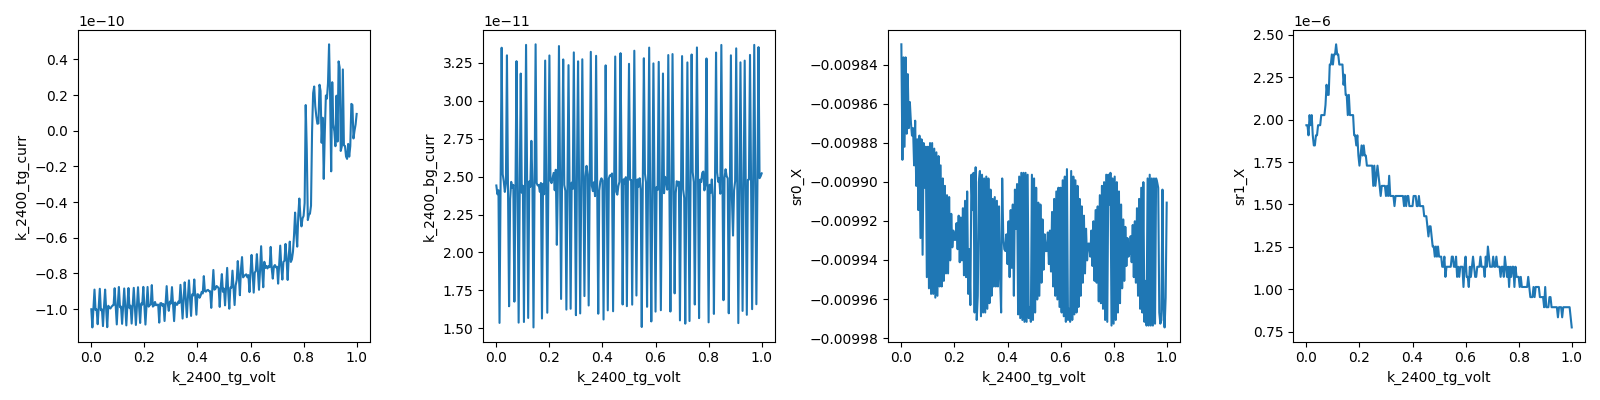

2026-08-21 20:32:45,932 [INFO] Completed in 0h 8m 33s


2026-08-21 20:32:45,932 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260821-vti-02\data\0\data.tsv.gz


2026-08-21 20:32:46,452 [INFO] Ramping k_2400_tg_volt: 1.0 -> 0


2026-08-21 20:32:48,223 [INFO] Ramping k_2400_tg_volt: 0.0 -> 0


2026-08-21 20:32:48,738 [INFO] Ramping k_2400_bg_volt: 0.0 -> 0


2026-08-21 20:32:48,753 [INFO] Starting sweep with ID 1


2026-08-21 20:32:48,754 [INFO] Minimum duration 0h 4m 11s


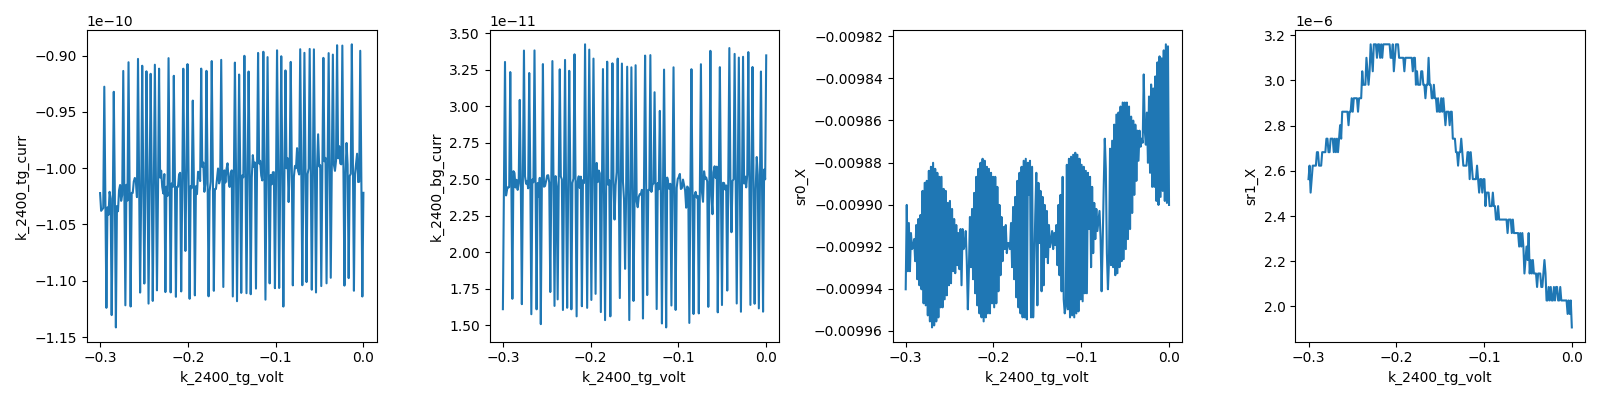

2026-08-21 20:41:22,926 [INFO] Completed in 0h 8m 33s


2026-08-21 20:41:22,926 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260821-vti-02\data\1\data.tsv.gz


2026-08-21 20:41:23,439 [INFO] Ramping k_2400_tg_volt: -0.3 -> 0


2026-08-21 20:41:24,339 [INFO] Ramping k_2400_tg_volt: 0.0 -> 0


2026-08-21 20:41:24,854 [INFO] Ramping k_2400_bg_volt: 0.0 -> 0


2026-08-21 20:41:24,869 [INFO] Starting sweep with ID 2


2026-08-21 20:41:24,870 [INFO] Minimum duration 0h 4m 11s


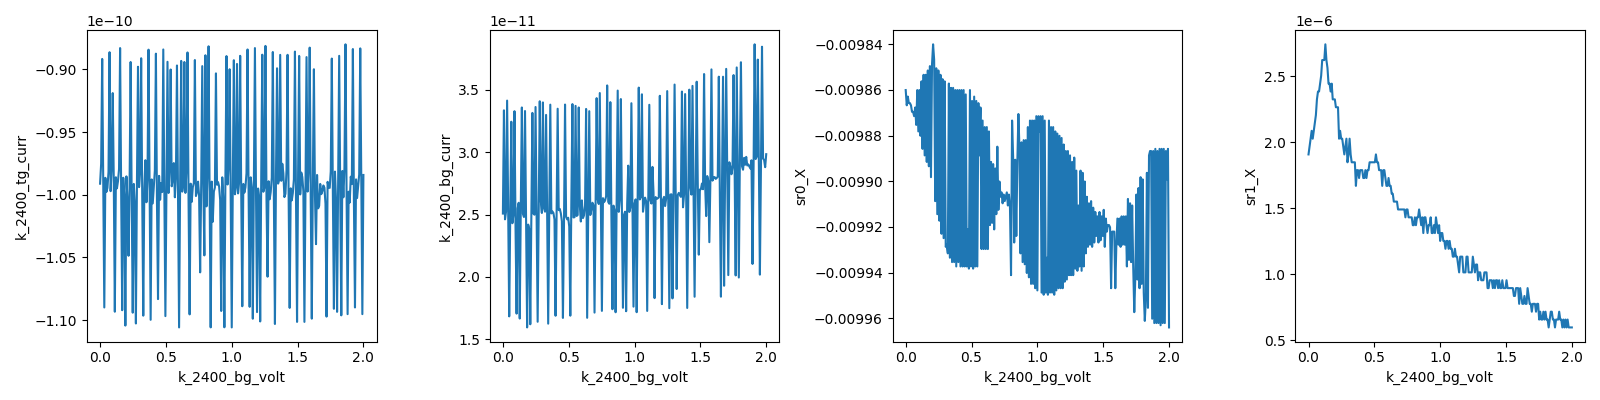

2026-08-21 20:50:02,531 [INFO] Completed in 0h 8m 36s


2026-08-21 20:50:02,532 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260821-vti-02\data\2\data.tsv.gz


2026-08-21 20:50:03,043 [INFO] Ramping k_2400_bg_volt: 2.0 -> 0


2026-08-21 20:50:06,082 [INFO] Ramping k_2400_tg_volt: 0.0 -> 0


2026-08-21 20:50:06,595 [INFO] Ramping k_2400_bg_volt: 0.0 -> 0


2026-08-21 20:50:06,611 [INFO] Starting sweep with ID 3


2026-08-21 20:50:06,612 [INFO] Minimum duration 0h 4m 11s


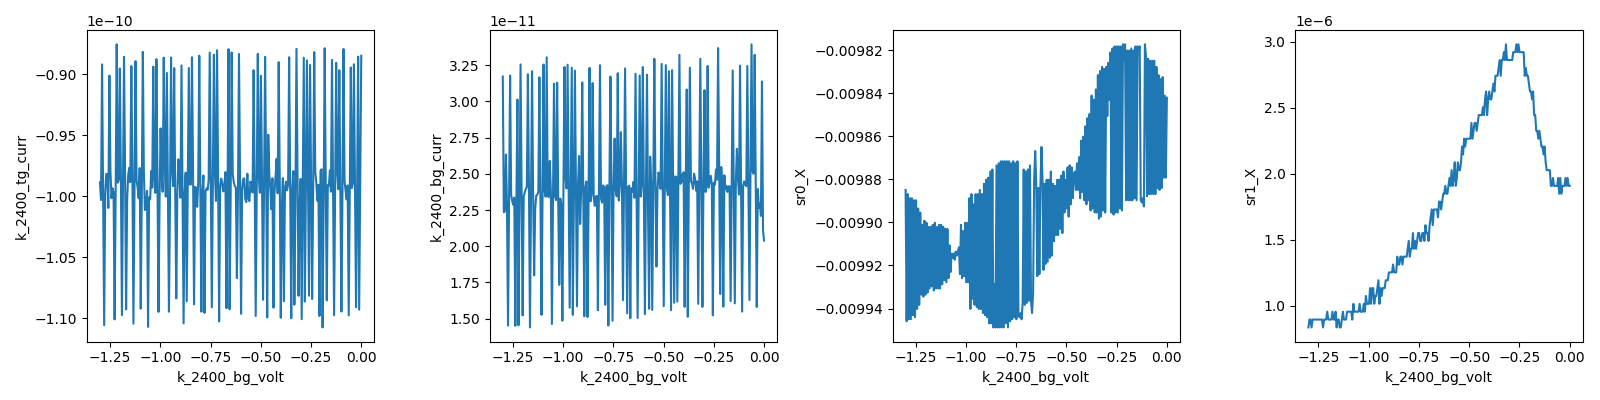

2026-08-21 20:58:43,837 [INFO] Completed in 0h 8m 36s


2026-08-21 20:58:43,838 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260821-vti-02\data\3\data.tsv.gz


2026-08-21 20:58:44,350 [INFO] Ramping k_2400_bg_volt: -1.3 -> 0


nplci reset: tg 1.0, bg 1.0 | gates: tg +0.0000 V, bg +0.0000 V


In [19]:
# === Gate C — gate-current-sanity-check: every gate 0 -> each card limit ===
# Precondition reads (state this cell assumes but does not set): stop on mismatch.
_Ts, _B, _Vsi = T_sample(), magnet.field(), dc205.voltage()
_rs, _rv = heater.sample_range(), heater.vaporizer_range()
print(f"pre: T_sample={_Ts:.3f} K (want 1.05-1.45) | B={_B:+.4f} T (want |B|<0.02) | Si={_Vsi:+.3f} V (want 0) | heater ranges={_rs},{_rv} (want 0,0)")
assert 1.05 <= _Ts <= 1.45, "T_sample out of base band"
assert abs(_B) < 0.02, "magnet not at zero"
assert abs(_Vsi) < 0.01, "Si gate not at 0"
assert _rs == 0 and _rv == 0, "a heater range is on"
# Keithley state, read-first (no writes): mode VOLT, rangev 21, rangei 1 uA, nplci 1, averaging off, 0 V.
# The 2400 reports its 1 uA range as 1.05e-6 (cell [18]); pass that so the 0.1 % compare holds.
assert_keithley_state(k_2400_tg, rangei=1.05e-6)
assert_keithley_state(k_2400_bg, rangei=1.05e-6)
print(f"compliance: tg {k_2400_tg.compliancei()} A, bg {k_2400_bg.compliancei()} A | output: tg {k_2400_tg.output()}, bg {k_2400_bg.output()}")

# Lock-in scale for the liveness read: sr1 was railed at sens 2 uV (X = 2.02 uV at (0,0)).
# 10 nA bias -> 1 mV full scale = 100 kOhm; tau 0.3 -> 0.1 s so a 1 s dwell is 10*tau at 24 dB/oct
# (2f = 27.6 Hz still rejected by ~100 dB at tau = 0.1 s). Recorded here; state0 holds the bring-up values.
sr1.sensitivity(1e-3)
sr0.time_constant(0.1); sr1.time_constant(0.1)
print(f"sr0 sens={sr0.sensitivity()} tau={sr0.time_constant()} | sr1 sens={sr1.sensitivity()} tau={sr1.time_constant()} | drive {sr1.amplitude()} V -> I_bias {sr1.amplitude()/meas_config['bias_resistor']*1e9:.1f} nA")

# one leg per gate per polarity, (gate, endpoint) — endpoints are the committed card limits
legs = [(k_tg, TG_MAX), (k_tg, TG_MIN), (k_bg, BG_MAX), (k_bg, BG_MIN)]
n_pts, delay = 251, 1.0

# pA-floor gate-current readback for this check; reset to 1 in the finally block.
k_tg.nplci(10); k_bg.nplci(10)
try:
    for gate, v_endpoint in legs:
        other = k_bg if gate is k_tg else k_tg
        mc = dict(meas_config)
        mc["comments"] = f"gate-current-sanity-check; {gate.name} 0 -> {v_endpoint:+g} V, {other.name} at 0, Si 0, B 0, 10 nA"
        s = sweep.AsyncStation(mc)
        s.add_comment('gate-current-sanity-check')
        s.add_comment(f'gate: {gate.name}')
        s.add_comment(f'leg: 0 -> {v_endpoint:+g} V (card limit); {other.name} parked at 0; Si = 0 V; B = 0 T')
        s.ramp(k_tg.volt, 0); s.ramp(k_bg.volt, 0)
        xp = gate.volt
        s.fp(T_sample)
        s.fp(other.volt)
        s.fp(gate.curr).fp(other.curr)
        s.fp(sr0.X).fp(sr0.P).fp(sr1.X).fp(sr1.P)
        s.plot(xp, k_tg.curr); s.plot(xp, k_bg.curr)
        s.plot(xp, sr0.X); s.plot(xp, sr1.X)
        try:
            s.sweep(gate.volt, np.linspace(0, v_endpoint, n_pts), delay=delay)
        finally:
            s.ramp(gate.volt, 0)
finally:
    k_tg.nplci(1); k_bg.nplci(1)
    print(f"nplci reset: tg {k_tg.nplci()}, bg {k_bg.nplci()} | gates: tg {k_tg.volt():+.4f} V, bg {k_bg.volt():+.4f} V")


## HERA — Step 1: first gatemap, full validator box at B = 0 (`gatemap` → `cnp-and-dline-calibration`)

> **21:00** · gatemap: B=0, Si=0; TG -0.3..+1.0 V fast (66 pts, 20 mV) x BG -1.3..+2.0 V slow (67 rows, 50 mV); 10 nA, sr1 sens 50 uV, tau 0.1 s, fast\_delay 0.7 s; 1 nA leak guard · **ETA ~22:20** (≈1h20m)

Gate C (runs 0–3) passed: drain current 9.8–9.97 nA on every leg (full bias reaching B_3), sr1 R_xx 60–320 Ω smooth and structured, gate currents flat to every limit (TG −100 pA offset, BG +25 pA; |I| < 115 pA everywhere, no turn-up; TG noise widens above +0.8 V but stays < 50 pA). Zero-gate state is electron-doped: R_xx maxima at V_tg = −0.22 V (V_bg = 0, run 1) and V_bg = −0.25 V (V_tg = 0, run 3) both give n_offset ≈ +0.38 × 10¹² cm⁻² on the geometry prior — one CNP ridge, inside the box. A secondary R_xx peak ≈ 0.18 × 10¹² above the CNP on the electron side appears in both run 0 (V_tg +0.10) and run 2 (V_bg +0.12) — a density feature, opposite D signs — recorded, not read.

This map is Step 1 of the investigation: the CNP ridge per row → CNP-line slope (c_bg/c_tg data-calibrated), intercept → n_offset, clean hole/electron regions, arms going insulating, and the D = 0 line design. Grid 66 (TG, 20 mV, fast) × 67 (BG, 50 mV, slow) = 4422 pts; the ridge FWHM ≈ 0.15 V on TG (run 1) is ~7 points wide at 20 mV, enough for the smoothed-argmax extraction. On the geometry prior the ridge crosses the box for V_bg ≲ −0.1 V (≈ 25 rows) — the slope fit's lever. Price: NPLC 1 readback ≈ 0.25 s + 0.7 s dwell (7τ at τ = 0.1 s, 24 dB/oct) ≈ 0.95 s/pt → 70 min + 67 × ~2.6 s row turnaround ≈ 73 min; headline 1h20m (gate C ran 2.05 s/pt at NPLC 10 + 1 s, run 0). sr1 sensitivity 50 µV = 5 kΩ full scale (0.3 Ω readback resolution; 1 mV gave a 6 Ω staircase in run 0) — corners above 5 kΩ rail flat, accepted for a first map. In-sweep leak guard at 1 nA interrupts cleanly (partial data kept, gates parked).

Coverage note: the D = 0 line reaches n ≈ −0.67 to +3.9 × 10¹² cm⁻² (geometry prior, n_offset +0.38): the hole side at D ≈ 0 is confined to the low-|n| exception regime by the TG limit (−0.3 V). The electron side is where the fan can go; the map tells whether a small-D hole region is usable.

Checkpoints: first rows via `hera-watch` (railing / leakage / flat channel); mid-map read at ~row 30 (ridge visible?) — continue / abandon.


pre: T_sample=1.184 K (want 1.05-1.45) | B=+0.0062 T (want |B|<0.02) | Si=+0.000 V (want 0) | heater ranges=0,0 | nplci tg 1.0 bg 1.0 (want 1)


sr0 sens=0.02 tau=0.1 | sr1 sens=5e-05 tau=0.1 | I_bias 10.0 nA
2026-08-21 21:00:37,253 [INFO] Ramping k_2400_tg_volt: 0.0 -> -0.3


2026-08-21 21:00:37,705 [INFO] Ramping k_2400_bg_volt: 0.0 -> -1.3


2026-08-21 21:00:44,366 [INFO] Starting megasweep with ID 4


2026-08-21 21:00:44,367 [INFO] Minimum duration 0h 52m 42s


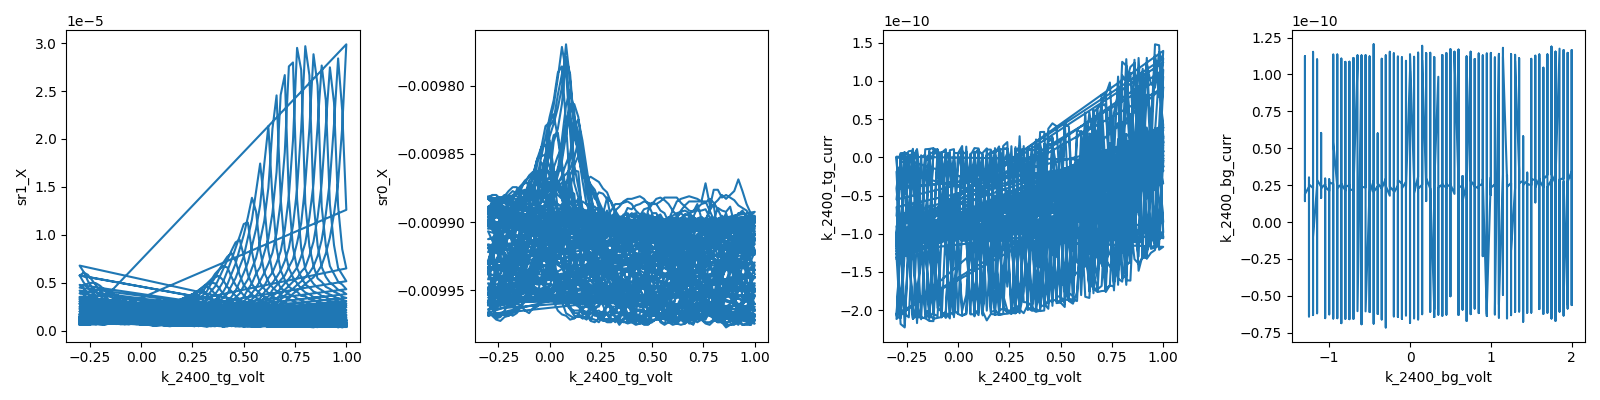

2026-08-21 22:02:59,208 [INFO] Completed in 1h 2m 13s


2026-08-21 22:02:59,208 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260821-vti-02\data\4\data.tsv.gz


gates parked: tg +0.0000 V, bg +0.0000 V


In [20]:
# === Step 1 — gatemap: full validator box at B = 0, Si = 0 (CNP location + (n, D) calibration input) ===
# Precondition reads (assumed, not set): stop on mismatch.
_Ts, _B, _Vsi = T_sample(), magnet.field(), dc205.voltage()
_rs, _rv = heater.sample_range(), heater.vaporizer_range()
print(f"pre: T_sample={_Ts:.3f} K (want 1.05-1.45) | B={_B:+.4f} T (want |B|<0.02) | Si={_Vsi:+.3f} V (want 0) | heater ranges={_rs},{_rv} | nplci tg {k_tg.nplci()} bg {k_bg.nplci()} (want 1)")
assert 1.05 <= _Ts <= 1.45 and abs(_B) < 0.02 and abs(_Vsi) < 0.01 and _rs == 0 and _rv == 0
assert k_tg.nplci() == 1 and k_bg.nplci() == 1, "gate-current NPLC not reset to 1"

# Lock-in scale: gate C legs (runs 0-3) put Rxx in 60-320 Ohm at 10 nA; sr1 readback quantizes at
# ~1/16000 of full scale (run 0: 60 nV steps at 1 mV sens = 6 Ohm staircase), so sens sits near the signal:
# 50e-6 V full scale = 5000 Ohm at 10 nA (0.3 Ohm resolution). Railing above 5000 Ohm is accepted
# (gapped corners flat-top; the D~0 ridge is what this map is for).
sr1.sensitivity(50e-6)
print(f"sr0 sens={sr0.sensitivity()} tau={sr0.time_constant()} | sr1 sens={sr1.sensitivity()} tau={sr1.time_constant()} | I_bias {sr1.amplitude()/meas_config['bias_resistor']*1e9:.1f} nA")

# Grid: TG fast (1.3 V span, flyback ~1.6 s at 5 mV/6 ms), BG slow.
vtg_vec = np.linspace(TG_MIN, TG_MAX, 66)   # 20 mV
vbg_vec = np.linspace(BG_MIN, BG_MAX, 67)   # 50 mV
fast_delay, slow_delay = 0.7, 1.0               # dwell 7 tau at 24 dB/oct (tau 0.1 s) + 1 s row settle
LEAK_ABORT = 1e-9  # A — in-sweep guard: clean interrupt (partial data kept, gates parked in finally)

mc = dict(meas_config)
mc["comments"] = f"gatemap; B=0, Si=0, TG {TG_MIN}..{TG_MAX} ({len(vtg_vec)} fast) x BG {BG_MIN}..{BG_MAX} ({len(vbg_vec)} slow), 10 nA, sr1 sens {sr1.sensitivity()}"
s = sweep.AsyncStation(mc)
s.add_comment('gatemap')
s.add_comment(f'first map, full validator box: TG {TG_MIN:+g}..{TG_MAX:+g} V fast ({len(vtg_vec)} pts), BG {BG_MIN:+g}..{BG_MAX:+g} V slow ({len(vbg_vec)} rows); Si = 0 V; B = 0 T; I = 10 nA')
s.fp(T_sample)
s.fp(k_tg.curr).fp(k_bg.curr)
s.fp(sr0.X).fp(sr0.P).fp(sr1.X).fp(sr1.P)
# row layout: [time, slow(bg), fast(tg), T_sample, I_tg, I_bg, sr0X, sr0P, sr1X, sr1P]
def _leak_guard(data, station):
    if abs(data[4]) > LEAK_ABORT or abs(data[5]) > LEAK_ABORT:
        print(f"LEAK GUARD: I_tg={data[4]:.2e} A, I_bg={data[5]:.2e} A at (tg {data[2]:+.3f}, bg {data[1]:+.3f}) — interrupting")
        station.interrupt_requested = True
s.register_run_after(_leak_guard, ())
s.plot(k_tg.volt, sr1.X); s.plot(k_tg.volt, sr0.X)
s.plot(k_tg.volt, k_tg.curr); s.plot(k_bg.volt, k_bg.curr)

s.ramp(k_tg.volt, vtg_vec[0]); s.ramp(k_bg.volt, vbg_vec[0])
interruptible_sleep(5)
try:
    s.megasweep(k_bg.volt, vbg_vec, k_tg.volt, vtg_vec, slow_delay=slow_delay, fast_delay=fast_delay)
finally:
    k_tg.volt(0); k_bg.volt(0)
    print(f"gates parked: tg {k_tg.volt():+.4f} V, bg {k_bg.volt():+.4f} V")


## HERA — Step 3: SdH spot check, electron side, D = 0, n = +3.0 × 10¹² (`sdh-spot-check`)

> **22:07** · sdh-spot-check electron: (n, D) = (+3.0e12, 0) -> (Vtg, Vbg) = (+0.879, +1.209) V; B 0 -> 10 T, 417 pts uniform dB 24 mT; 10 nA, sr1 autorange from 2 uV, tau 0.1 s, dwell 0.7 s; field left at 10 T · **ETA ~23:57** (≈1h50m)

Run 4 (ana cells 13–15) calibrated the gates: CNP line V_tg = −0.727·V_bg + 0.040 (rows V_bg −1.25…−0.2, rms 18 mV) ⇒ c_bg/c_tg = 0.727 data-calibrated (prior 0.864; 16 % off — window-dependent at ±10 % from a mildly curved ridge; scale stays the geometry prior with c_tg anchored), n_offset −0.07 × 10¹², D_offset 0 (the gap minimum sits at geometric D = +0.006 V/nm). The D = 0 line realizes n = −1.1…+3.4 × 10¹². A second, V_bg-independent R_xx maximum at V_tg ≈ −0.2 V is a TG-only-gated stretch of the B_1–B_2 path — it is what the gate-C single-gate scans found; on the hole side it is driven to neutrality, so the electron side is the side the gate limits *and* the device geometry leave (no side prior was available to exercise; the hole check is still planned as a ride-down at |n| ≈ 1 × 10¹²).

**Step 2 (computed, model table in scratch/feasibility_step2.md):** at n = +3.0 × 10¹², F_L = 31.0 T; ABAB pair 6.7 / 24.4 T (m* 0.027 / 0.060), ABCA singleton 31.0 T (0.076). Δ(1/B) = 1/(3·F_L) = 0.0108 T⁻¹ → uniform-B step ΔB = Δ(1/B)·B_lo² = 24 mT at B_lo = 1.5 T (blocking magnet: sample uniform in B, Nyquist held at the low edge). Partner tone ≥ 5 periods needs a 1/B span ≥ 0.75 T⁻¹ → B_lo ≤ 1.2 T at B_max = 10 T; heavy-ABAB vs ABCA separation (6.6 T) needs δF ≤ 3.3 T → usable record from ≤ 2.5 T. Onset is measured here, not assumed. Sweep 0 → 10 T (417 pts) — the magnet sits at 0, the sub-1.5 T leg is the onset/MR read and costs ~15 min.

Gate point (+0.879, +1.209) V — inside the validators; R_xx = 54 Ω at B = 0 (0.54 µV at 10 nA). Lock-in: `autorange_sr830s` run-before hook on sr1 (sr0 phase ≈ 180° is its validity check) keeps the readback in range as the MR grows — a fixed scale sized for 10 T would digitize the low-B oscillations (1/16000-of-range quantization, run 0). τ 0.1 s, dwell 0.7 s. Price: traverse 73 min (0.137 T/min) + 417 × (3 s settle + 0.7 s dwell + ~0.4 s reads) ≈ 28 min → ~1h45m; the field is **left at 10 T** for the hole-side ride-down. Checkpoints: first rows (contacts, leak, autorange behaving), then at ~4 T (onset visible?); wash-out call if nothing oscillates by 8 T → the hole ride-down still pays for the traverse.


spot (n, D) = (+3.00e12, +0.00 V/nm) -> (Vtg, Vbg) = (+0.8793, +1.2093) V; roundtrip (3.0, 0.0)
pre: T_sample=1.181 K | B=+0.0062 T (want |B|<0.02) | Si=+0.000 V | heater ranges=0,0 | output=True PS=True


B grid: 417 pts, 0 -> 10.0 T, dB = 24.0 mT | sr1 start sens 2e-06 (autorange) tau 0.1 | magnet settle_s 3.0
2026-08-21 22:07:39,124 [INFO] Ramping k_2400_tg_volt: 0.0 -> 0.879274720100497


2026-08-21 22:07:40,284 [INFO] Ramping k_2400_bg_volt: 0.0 -> 1.2093163034299064


gates at (+0.8795, +1.2095) V; starting field sweep
2026-08-21 22:07:51,952 [INFO] Starting sweep with ID 5


2026-08-21 22:07:51,953 [INFO] Minimum duration 0h 4m 51s


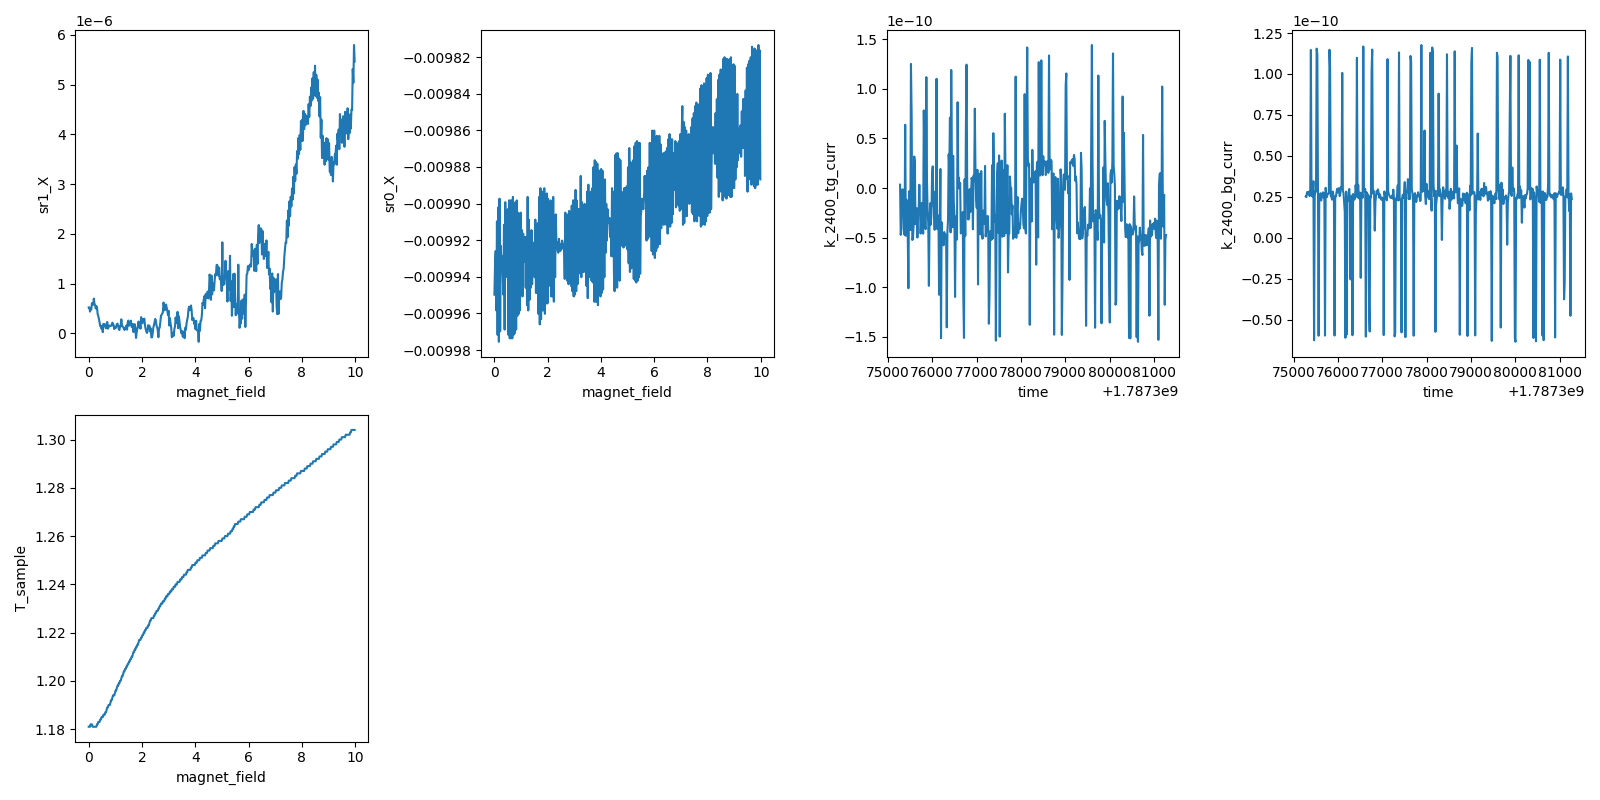

2026-08-21 23:47:55,529 [INFO] Completed in 1h 40m 2s


2026-08-21 23:47:55,530 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260821-vti-02\data\5\data.tsv.gz


done: B = +9.994 T (left at B_MAX for the hole-side ride-down); gates held at the electron point


In [21]:
# === Step 3 — sdh-spot-check, electron side, D = 0: B 0 -> 10 T, uniform in B ===
# Calibration committed from run 4 (cnp-and-dline-calibration): ratio data-calibrated, scale geometry prior.
C_TG = 2.7961e-3          # F/m^2, stack prior (9.5 nm hBN), anchor
C_BG = 2.0330e-3          # F/m^2, from the CNP-line slope -dVtg/dVbg = 0.7271 (run 4, rows Vbg -1.25..-0.2, rms 18 mV)
N_OFFSET = -0.069     # 1e12 cm^-2, from the CNP-line intercept (sharpelab_nb.gates units)
D_OFFSET = 0.0          # V/nm — stated assumption: D = 0 taken at the geometric symmetric point (run 4 read: ridge-R minimum at geometric D = +0.006 V/nm, so the gap minimum and the geometry agree)
from sharpelab_nb.gates import calc_gate_voltages, calc_nD
cal_s = GateCalibration(C_TG, C_BG, n_offset=N_OFFSET * 1e16, D_offset=D_OFFSET * 1e9)

N_SPOT, D_SPOT = 3.0, 0.0   # 1e12 cm^-2, V/nm
Vtg_spot, Vbg_spot = calc_gate_voltages(N_SPOT, D_SPOT, C_TG, C_BG, n_offset=N_OFFSET, D_offset=D_OFFSET)
assert TG_MIN <= Vtg_spot <= TG_MAX and BG_MIN <= Vbg_spot <= BG_MAX, (Vtg_spot, Vbg_spot)
print(f"spot (n, D) = ({N_SPOT:+.2f}e12, {D_SPOT:+.2f} V/nm) -> (Vtg, Vbg) = ({Vtg_spot:+.4f}, {Vbg_spot:+.4f}) V; roundtrip {calc_nD(Vtg_spot, Vbg_spot, C_TG, C_BG, N_OFFSET, D_OFFSET)}")

# Precondition reads (assumed, not set)
_Ts, _B, _Vsi = T_sample(), magnet.field(), dc205.voltage()
_rs, _rv = heater.sample_range(), heater.vaporizer_range()
_st = magnet._status()
print(f"pre: T_sample={_Ts:.3f} K | B={_B:+.4f} T (want |B|<0.02) | Si={_Vsi:+.3f} V | heater ranges={_rs},{_rv} | output={_st['output_enabled']} PS={_st['persistent_switch_on']}")
assert 1.05 <= _Ts <= 1.45 and abs(_B) < 0.02 and abs(_Vsi) < 0.01 and _rs == 0 and _rv == 0
assert _st['output_enabled'] and _st['persistent_switch_on']

# Field grid: uniform in B, dB = Δ(1/B)·B_lo² with Δ(1/B) = 1/(3·F_L(n_spot)) = 0.0108 T^-1, B_lo = 1.5 T -> dB = 24 mT.
# Sweep from 0 (magnet is at 0; the sub-onset leg is the low-field MR + onset read, ~62 extra pts).
B_MAX = 10.0
assert B_MAX <= B_SESSION_CAP
B_vec = np.arange(0.0, B_MAX + 1e-9, 0.024)
# Lock-in: Rxx at this point is 54 Ohm at B = 0 (run 4) = 0.54 uV at 10 nA; the readback quantizes at ~1/16000 of
# full scale, so a fixed scale sized for the high-B MR would digitize the low-B oscillations. Use the corpus
# autorange hook (sharpelab_nb.autorange.autorange_sr830s: keeps sr1 between 10 % and 90 % of its range, 10 tau
# wait per change, floor 1 uV) as a run_before hook; the current channel (sr0, ~180 deg) is its validity check.
from sharpelab_nb.autorange import autorange_sr830s
sr1.sensitivity(2e-6)
dwell = 0.7
print(f"B grid: {len(B_vec)} pts, 0 -> {B_MAX} T, dB = {np.diff(B_vec)[0]*1e3:.1f} mT | sr1 start sens {sr1.sensitivity()} (autorange) tau {sr1.time_constant()} | magnet settle_s {getattr(magnet, 'settle_s', None)}")

mc = dict(meas_config)
mc["comments"] = f"sdh-spot-check; electron, (n, D) = ({N_SPOT:+.2f}e12, {D_SPOT:+.2f}), (Vtg, Vbg) = ({Vtg_spot:+.4f}, {Vbg_spot:+.4f}), B 0 -> {B_MAX} T uniform dB {np.diff(B_vec)[0]*1e3:.1f} mT, 10 nA, Si 0"
s = sweep.AsyncStation(mc)
s.add_comment('sdh-spot-check')
s.add_comment(f'electron side, D = 0: n = {N_SPOT:+.2f}e12 cm^-2, (Vtg, Vbg) = ({Vtg_spot:+.4f}, {Vbg_spot:+.4f}) V; B = 0 -> {B_MAX} T, {len(B_vec)} pts uniform-B (dB {np.diff(B_vec)[0]*1e3:.1f} mT = 1/(3 F_L) at B_lo {1.5} T); I = 10 nA; Si = 0 V')
s.add_comment(f'calibration: c_tg {C_TG:.4e} (prior), c_bg {C_BG:.4e} (ratio from run 4 CNP slope), n_offset {N_OFFSET:+.3f}e12, D_offset {D_OFFSET}')
s.register_run_before(autorange_sr830s, (sr0, [sr1]))
s.fp(T_sample).fp(T_vaporizer)
s.fp(k_tg.volt).fp(k_bg.volt)
s.fp(k_tg.curr).fp(k_bg.curr)
s.fp(sr0.X).fp(sr0.P).fp(sr1.X).fp(sr1.P)
s.plot(magnet.field, sr1.X); s.plot(magnet.field, sr0.X)
s.plot('time', k_tg.curr); s.plot('time', k_bg.curr); s.plot(magnet.field, T_sample)

s.ramp(k_tg.volt, Vtg_spot); s.ramp(k_bg.volt, Vbg_spot)
interruptible_sleep(10)
print(f"gates at ({k_tg.volt():+.4f}, {k_bg.volt():+.4f}) V; starting field sweep")
s.sweep(magnet.field, B_vec, delay=dwell)
print(f"done: B = {magnet.field():+.3f} T (left at B_MAX for the hole-side ride-down); gates held at the electron point")


## HERA — Si-gate test of the TG-only series segment (two TG linecuts at B = 10 T, V_bg = 0)

> **23:50** · TG linecut x2 at B=10 T, Vbg=0: Si=0 (+1.0->-0.3 V) then Si=+25 V (-0.3->+1.0), 66 pts, 0.7 s dwell, sr1 autorange; Si back to 0 at end · **ETA ~23:56** (≈6 min)

Run 5 landed clean (next cells carry the read). The magnet sits at 10 T and the gates at the electron point; before committing the fan, a 5-minute question the map raised: the V_bg-independent R_xx maximum at V_tg ≈ −0.2 V (run 4) is a top-gate-only-gated stretch of the B_1–B_2 path — a confound on the hole side (it is driven to neutrality there) and a possible extra SdH tone tracking V_tg on the electron side. The Si gate couples only to the un-backgated (contact) regions, so if that stretch is Si-coupled, Si = +25 V moves its CNP in V_tg. Two 66-pt TG scans at V_bg = 0, B = 10 T, one station: Si = 0 (+1.0 → −0.3 V), Si ramped to +25 V at the committed 0.5 V/s, scan back (−0.3 → +1.0), Si returned to 0. Inside the validators (Si ±25 V); the DC205 pacing is untouched. The dual-gated CNP (V_tg ≈ +0.04 at V_bg = 0) is screened from Si and should not move — that is the control. ~5 min.


pre: T_sample=1.304 K | B=+9.9902 T (want ~10) | Si=+0.000 V (want 0) | heater ranges=0,0 | gates (+0.8795, +1.2095)
2026-08-21 23:50:05,251 [INFO] Ramping k_2400_bg_volt: 1.2095 -> 0.0


2026-08-21 23:50:06,836 [INFO] Ramping k_2400_tg_volt: 0.8795 -> 1.0


2026-08-21 23:50:11,997 [INFO] Starting sweep with ID 6


2026-08-21 23:50:11,998 [INFO] Minimum duration 0h 0m 46s


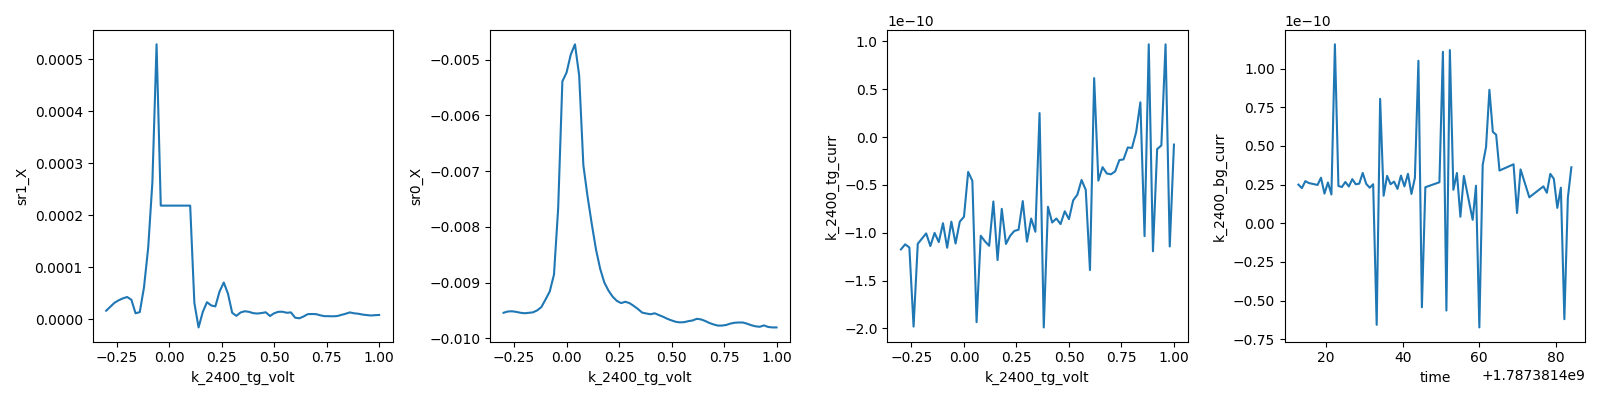

2026-08-21 23:51:24,744 [INFO] Completed in 0h 1m 12s


2026-08-21 23:51:24,745 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260821-vti-02\data\6\data.tsv.gz


2026-08-21 23:51:24,762 [INFO] Ramping dc205_smart_voltage: 0.0 -> 25.0


Si readback +25.000 V
2026-08-21 23:52:44,836 [INFO] Starting sweep with ID 7


2026-08-21 23:52:44,837 [INFO] Minimum duration 0h 0m 46s


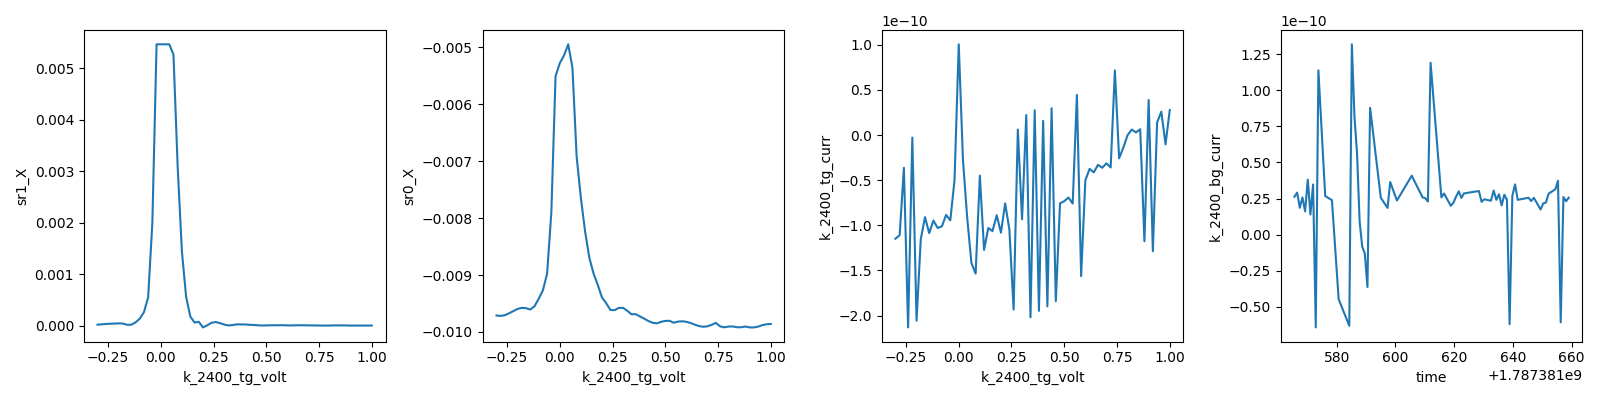

2026-08-21 23:54:19,715 [INFO] Completed in 0h 1m 34s


2026-08-21 23:54:19,716 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260821-vti-02\data\7\data.tsv.gz


2026-08-21 23:54:19,722 [INFO] Ramping dc205_smart_voltage: 25.0 -> 0.0


done; Si left at +0.000 V, gates (+1.0000, +0.0000), B +9.990 T


In [22]:
# === Si-gate test of the TG-only series segment, at B = 10 T: TG scan at V_bg = 0 with Si = 0, then Si = +25 V ===
# Precondition reads (assumed, not set)
_Ts, _B, _Vsi = T_sample(), magnet.field(), dc205.voltage()
_rs, _rv = heater.sample_range(), heater.vaporizer_range()
print(f"pre: T_sample={_Ts:.3f} K | B={_B:+.4f} T (want ~10) | Si={_Vsi:+.3f} V (want 0) | heater ranges={_rs},{_rv} | gates ({k_tg.volt():+.4f}, {k_bg.volt():+.4f})")
assert 1.05 <= _Ts <= 1.45 and abs(_B - 10.0) < 0.05 and abs(_Vsi) < 0.01 and _rs == 0 and _rv == 0
SI_TEST = 25.0
assert SI_MIN <= SI_TEST <= SI_MAX and dc205.ramp_rate == 0.5   # pacing unchanged (consent-gated)
from sharpelab_nb.autorange import autorange_sr830s
vtg_down = np.linspace(TG_MAX, TG_MIN, 66)   # start where the gates sit (+0.88 -> +1.0 is a 0.12 V move)
vtg_up = vtg_down[::-1]

mc = dict(meas_config)
mc["comments"] = f"gate-axis TG scan at B = 10 T, Vbg = 0: Si = 0 then Si = {SI_TEST:+g} V — does Si dope the TG-only series segment (CNP at Vtg ~ -0.2 V, run 4)?"
s = sweep.AsyncStation(mc)
s.add_comment('gatemap')   # 1D gate-axis cut; the map recipe's slug for a V_tg line (no dedicated linecut recipe on this rig)
s.add_comment(f'TG linecut at Vbg = 0, B = 10 T, I = 10 nA; two runs on one station: Si = 0 V (Vtg {TG_MAX:+g} -> {TG_MIN:+g}), then Si = {SI_TEST:+g} V (Vtg {TG_MIN:+g} -> {TG_MAX:+g}); purpose: Si response of the Vbg-independent Rxx maximum at Vtg ~ -0.2 V (TG-only-gated series segment)')
s.register_run_before(autorange_sr830s, (sr0, [sr1]))
s.fp(T_sample).fp(k_bg.volt).fp(k_si)
s.fp(k_tg.curr).fp(k_bg.curr)
s.fp(sr0.X).fp(sr0.P).fp(sr1.X).fp(sr1.P)
s.plot(k_tg.volt, sr1.X); s.plot(k_tg.volt, sr0.X); s.plot(k_tg.volt, k_tg.curr); s.plot('time', k_bg.curr)

s.ramp(k_bg.volt, 0.0); s.ramp(k_tg.volt, vtg_down[0])
interruptible_sleep(5)
s.sweep(k_tg.volt, vtg_down, delay=0.7)                      # Si = 0
mc["Si (V)"] = SI_TEST
s.ramp(k_si, SI_TEST)                                         # DC205 ramped set at 0.5 V/s (~50 s), validators fence it
interruptible_sleep(30)
print(f"Si readback {dc205.voltage():+.3f} V")
s.sweep(k_tg.volt, vtg_up, delay=0.7)                        # Si = +25
s.ramp(k_si, 0.0)                                             # back to the spot-check / fan conditions (Si = 0)
interruptible_sleep(5)
print(f"done; Si left at {dc205.voltage():+.3f} V, gates ({k_tg.volt():+.4f}, {k_bg.volt():+.4f}), B {magnet.field():+.3f} T")


## HERA — Step 4: Landau fan, electron side, D = 0, riding the magnet 10 → 2.4 T (`landau-fan-vti`)

> **23:55** · landau-fan-vti electron D=0: n 3.4->1.5e12 (41 pts, design frame x0.90), B 10->2.4 T uniform 1/B (36 rows, d(1/B) 0.0090); 10 nA, sr1 50 uV fixed, dwell 0.7 s; ends at 2.4 T · **ETA ~01:30 (+1d)** (≈1h35m)

Run 5 (ana cells 16–18) made the electron side the fan side: onset 2.4 T, a two-fundamental set 6.2 / 21.8 T with its sum (28.1 ≈ F_L) and difference (15.6) tones, Luttinger scale 0.90, partition 0.78/0.22 — ABAB-template-consistent at one density. The fan is the trajectory test the investigation requires before any call (Step 5: f₁(n)+f₂(n) = F_L(n) across density; the heavy branch at 0.78·F_L (ABAB) vs F_L (ABCA) vs ~0.87·F_L (trilayer ML+BL); the TG-only series-segment confound at ≈ 5.2·n + 4 T tracks V_tg, not n). The magnet sits at 10 T: the fan descends to the measured onset and ends at 2.4 T — no re-traverse; what happens at 2.4 T is decided after the read (hole-side work, LK ladder, or home).

**Design (computed, floored):** fast axis the D = 0 line n = 3.4 → 1.5 × 10¹² (run-4 calibration frame; ×0.90 actual), 41 points (Δn = 0.05 × 10¹²; the ray spacing at 2.4 T is 0.26 × 10¹² → 5 points per ray, above the ≥ 2 floor); V_tg 0.45…1.00, V_bg 0.42…1.38 (inside validators, clipped by dropping — none dropped). Slow axis `field_invB(10, 2.4, 36)`: Δ(1/B) = 0.0090 T⁻¹ = 1/(3.7·F_L) at the top density (F_L = 31.7 T actual) — Nyquist with margin; 36 rows because the 1/B record above onset is only 0.32 T⁻¹ (δF = 3.1 T per column, same as the spot check; the light tone stays coarse, the heavy tone has 7 periods — the discriminator). n_max = 3.4 is the validator ceiling on this line (V_tg = 1.0), n_min = 1.5 is where the ABAB heavy tone (≈ 11 T actual) still has ≥ 3.5 periods — below that the low-n exception regime and δF make columns uninformative, so they are not bought. Fixed sr1 scale 50 µV (5 kΩ; worst corner low-n × 10 T ≈ 1–2 kΩ with the Hall admixture; 0.3 Ω resolution vs ±20–150 Ω oscillations). Dwell 0.7 s (7τ), slow_delay 2 s on top of the 3 s field settle; 1 nA leak guard.

**Price:** traverse 7.6 T / 0.137 T/min = 55 min (rows ramp-limited: 60 mT at the low end, 1.0 T at the top) + 36 × (41 × 0.95 s + ~2 s flyback + 2 s) ≈ 26 min → ~1h25m; headline 1h35m (run 4 measured 0.84 s/pt at this dwell, run 5 measured the settle overhead). Checkpoints: first rows (scale, leak, gates tracking the line), then at row ~18 (B ≈ 4.2 T — both fundamentals should be visible per column) — continue / abandon.


pre: T_sample=1.304 K | B=+9.9902 T (want ~10) | Si=+0.000 V (want 0) | heater ranges=0,0 | output=True PS=True | nplci 1.0,1.0
n-line: 41 pts, n +1.50..+3.40 e12 (design frame), Vtg +0.450..+0.994, Vbg +0.618..+1.367
B rows: 36, 10.000 -> 2.400 T, d(1/B) = 0.0090 T^-1, dB 53..830 mT


sr1 sens 5e-05 tau 0.1 | I_bias 10.0 nA
2026-08-21 23:55:41,158 [INFO] Ramping k_2400_tg_volt: 1.0 -> 0.9938755308011157


2026-08-21 23:55:41,235 [INFO] Ramping k_2400_bg_volt: 0.0 -> 1.3669332866074764


2026-08-21 23:55:47,955 [INFO] Starting multimegasweep with ID 8


2026-08-21 23:55:47,956 [INFO] Minimum duration 0h 18m 25s


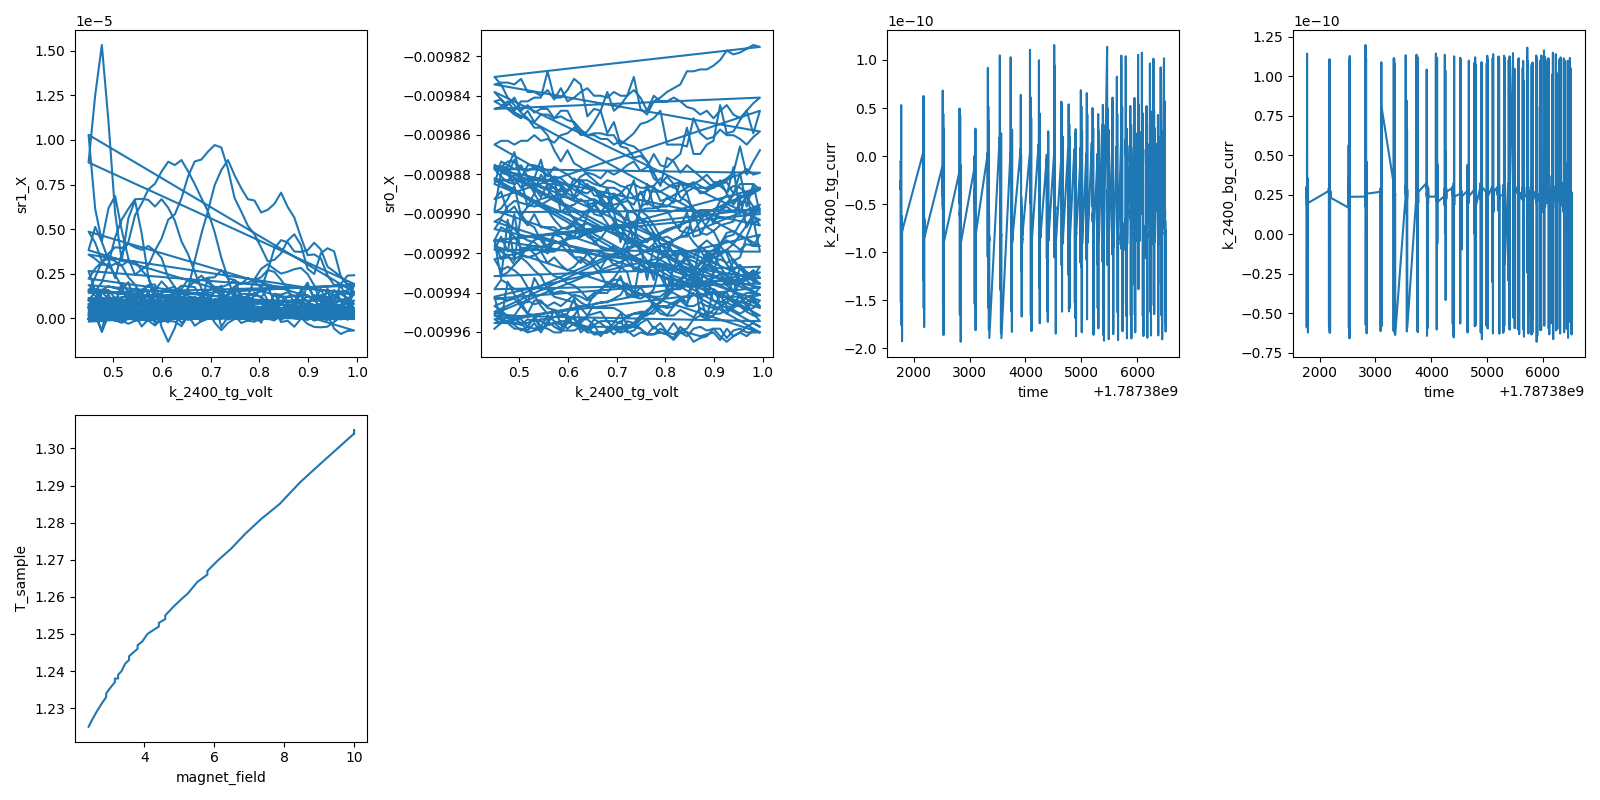

2026-08-22 01:15:14,781 [INFO] Completed in 1h 19m 26s


2026-08-22 01:15:14,782 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260821-vti-02\data\8\data.tsv.gz


end: B = +2.406 T (held; next step decides), gates (+0.4495, +0.6185) V


In [23]:
# === Step 4 — landau-fan-vti, electron side, D = 0: B 10 -> 2.4 T (uniform 1/B, slow) x n-line (fast) ===
from sharpelab_nb.gates import calc_gate_voltages, calc_nD
C_TG, C_BG, N_OFFSET, D_OFFSET = 2.7961e-3, 2.0330e-3, -0.069, 0.0   # run 4 calibration (prior scale; Luttinger scale 0.90 from run 5)

# Precondition reads (assumed, not set)
_Ts, _B, _Vsi = T_sample(), magnet.field(), dc205.voltage()
_rs, _rv = heater.sample_range(), heater.vaporizer_range()
_st = magnet._status()
print(f"pre: T_sample={_Ts:.3f} K | B={_B:+.4f} T (want ~10) | Si={_Vsi:+.3f} V (want 0) | heater ranges={_rs},{_rv} | output={_st['output_enabled']} PS={_st['persistent_switch_on']} | nplci {k_tg.nplci()},{k_bg.nplci()}")
assert 1.05 <= _Ts <= 1.45 and abs(_B - 10.0) < 0.05 and abs(_Vsi) < 0.01 and _rs == 0 and _rv == 0
assert _st['output_enabled'] and _st['persistent_switch_on']

# Fast axis: D = 0 line, n = 3.4 -> 1.5 (design frame = run-4 calibration; actual n = 0.90 x on the run-5 Luttinger scale)
ns = np.linspace(3.4, 1.5, 41)                 # dn = 0.0475e12 (prior frame); ray spacing at 2.4 T = 0.26e12 -> 5 pts/ray
Ds = np.zeros_like(ns)
Vtgs, Vbgs = calc_gate_voltages(ns, Ds, C_TG, C_BG, n_offset=N_OFFSET, D_offset=D_OFFSET)
Vtgs, Vbgs = sanitize_tg_bg(Vtgs, Vbgs, tg_lims, bg_lims)   # clip by dropping, never clamping
n_chk, D_chk = calc_nD(Vtgs, Vbgs, C_TG, C_BG, N_OFFSET, D_OFFSET)
assert np.allclose(D_chk, 0.0, atol=1e-6) and len(Vtgs) == len(ns), (len(Vtgs), D_chk.max())
print(f"n-line: {len(Vtgs)} pts, n {n_chk.min():+.2f}..{n_chk.max():+.2f} e12 (design frame), Vtg {Vtgs.min():+.3f}..{Vtgs.max():+.3f}, Vbg {Vbgs.min():+.3f}..{Vbgs.max():+.3f}")

# Slow axis: uniform in 1/B from 10 T (where the magnet sits) down to the measured onset 2.4 T (run 5).
# Nyquist: F_L at the top of the line = 31.7 T (actual) -> d(1/B) <= 1/(3 F_L) = 0.0105; 36 rows give 0.0090 (1/(3.7 F_L)).
B_vec = field_invB(10.0, 2.4, 36)
assert np.all(np.abs(B_vec) <= B_SESSION_CAP)
print(f"B rows: {len(B_vec)}, {B_vec[0]:.3f} -> {B_vec[-1]:.3f} T, d(1/B) = {np.diff(1/B_vec)[0]:.4f} T^-1, dB {np.abs(np.diff(B_vec)).min()*1e3:.0f}..{np.abs(np.diff(B_vec)).max()*1e3:.0f} mT")

# Fixed scale for the whole fan (no autorange inside a 2D map): worst corner is low n x 10 T, where the Hall admixture
# on this pair (alpha ~ 0.2, run 5) puts R ~ 1-2 kOhm; 50 uV = 5 kOhm full scale at 10 nA, 0.3 Ohm readback resolution
# against SdH amplitudes of +-20..150 Ohm (run 5).
sr1.sensitivity(50e-6)
fast_delay, slow_delay = 0.7, 2.0   # 7 tau at 24 dB/oct; the blocking field set already settles 3 s
print(f"sr1 sens {sr1.sensitivity()} tau {sr1.time_constant()} | I_bias {sr1.amplitude()/meas_config['bias_resistor']*1e9:.1f} nA")

mc = dict(meas_config)
mc["comments"] = f"landau-fan-vti; electron, D = 0, n {ns.max():.2f} -> {ns.min():.2f} e12 (design frame, x0.90 actual), B {B_vec[0]:.2f} -> {B_vec[-1]:.2f} T uniform 1/B {len(B_vec)} rows x {len(Vtgs)} pts, 10 nA, sr1 50 uV, Si 0"
s = sweep.AsyncStation(mc)
s.add_comment('landau-fan-vti')
s.add_comment(f'D = 0 V/nm, n = {ns.max():.2f} to {ns.min():.2f} e12 cm^-2 (run-4 calibration frame; Luttinger scale 0.90 from run 5), B = {B_vec[0]:.2f} to {B_vec[-1]:.2f} T uniform in 1/B ({len(B_vec)} rows, d(1/B) {np.diff(1/B_vec)[0]:.4f}); fast axis {len(Vtgs)} pts (Vtg, Vbg) line; I = 10 nA; Si = 0 V; sr1 sens 50 uV fixed')
s.add_comment(f'calibration: c_tg {C_TG:.4e} (prior), c_bg {C_BG:.4e} (run 4 CNP slope), n_offset {N_OFFSET:+.3f}e12, D_offset {D_OFFSET}')
s.fp(T_sample).fp(T_vaporizer)
s.fp(k_tg.curr).fp(k_bg.curr)
s.fp(sr0.X).fp(sr0.P).fp(sr1.X).fp(sr1.P)
# row layout: [time, B, Vtg, Vbg, T_sample, T_vap, I_tg, I_bg, sr0X, sr0P, sr1X, sr1P]
def _leak_guard(data, station):
    if abs(data[6]) > 1e-9 or abs(data[7]) > 1e-9:
        print(f"LEAK GUARD: I_tg={data[6]:.2e} A, I_bg={data[7]:.2e} A at B={data[1]:.3f}, (tg {data[2]:+.3f}, bg {data[3]:+.3f}) — interrupting")
        station.interrupt_requested = True
s.register_run_after(_leak_guard, ())
s.plot(k_tg.volt, sr1.X); s.plot(k_tg.volt, sr0.X)
s.plot('time', k_tg.curr); s.plot('time', k_bg.curr); s.plot(magnet.field, T_sample)

s.ramp(k_tg.volt, Vtgs[0]); s.ramp(k_bg.volt, Vbgs[0])
interruptible_sleep(5)
try:
    s.multimegasweep([magnet.field], [B_vec], [k_tg.volt, k_bg.volt], [Vtgs, Vbgs], slow_delay=slow_delay, fast_delay=fast_delay)
finally:
    print(f"end: B = {magnet.field():+.3f} T (held; next step decides), gates ({k_tg.volt():+.4f}, {k_bg.volt():+.4f}) V")


## HERA — Verify: LK mass split, electron spot point (`temperature-dependence-vti`, Flavor B) — in-arc

> **01:19** · LK ladder: rungs 4,7,10,14,20,28 K (set\_both ratio 0.95, hover acceptance), electron point (+0.879,+1.209) V, B 2.4<->10 T alternating, 317 pts 24 mT, 10 nA, autorange; heaters off at end, field ends at 10 T · **ETA ~09:19** (≈8h)

Run 8 (ana cells 22–25) leaves the B_1–B_2 region at **ABAB, consistent-with → strong candidate**: two branches on the ABAB curves (light 0.21·F_L across n, heavy 0.77·F_L for n ≳ 2.5), Luttinger-closed at one scale (0.93), the F_L tone strengthening with B where the split resolves (breakdown-like). The investigation's decisive discriminator for the F_L-tone origin and for "two genuine bands vs one band + artifact" is the **per-branch LK mass** — the ABAB branches differ by ≈ φ² (model at n ≈ 2.8: light 0.027, heavy 0.060 m_e; the breakdown orbit carries ≈ their sum, 0.09; an ABCA pocket would be 0.076 with no light partner). Flavor B: repeat run 5's field sweep (2.4 ↔ 10 T, 24 mT, 10 nA, autorange) at the same gate point (n = +3.0 design, D = 0) on a T ladder.

**Ladder design from the mass prior (base recipe):** X = 14.69·m*·T/B_eff with B_eff = 1/(mid 1/B) = 3.85 T; the light tone (m* ≈ 0.027) reaches X ≈ 3 only at ~30 K, the heavy/sum tones at 13–20 K. Rungs **4, 7, 10, 14, 20, 28 K**, ascending (up-legs catch in minutes on this rig; the base rung is run 5 at 1.18–1.30 K), `set_both(T, ratio = 0.95)` (no deviation), all ≤ the 100 K cap. VTI guard set in the cell: logfile-freshness on every poll (15 s / 12 s), **hover acceptance** (spread < 0.1 K over 90 s inside [T − 0.5, T + 3]), direction-aware **runaway guard** (T_vap > 2 K above both its rung-start value and the target → heaters off, stop), settle timeout 25 min (proceed only if stable, else stop). Sweep direction alternates from the live field (2.4 → 10, 10 → 2.4, …) — no re-traverse; the magnet ends at 10 T after the 6th rung (even count) — accepted, the close-out ramp is then 73 min. Heaters off in `finally`.

**Price:** per rung ≈ 3–5 min settle + 76 min sweep (55 min traverse + 317 × 4 s) → ~8 h for six rungs; checkpoints: each rung's run completion (amplitude-vs-T read appended to ana as it lands; the ladder extends or stops on the fit). He budget: not supplied by the operator (asked twice); proceeding on the grant, notified at start — the operator can stop any rung (`nb-collab interrupt` or at the rig).


In [24]:
# === Verify: LK mass split — temperature-dependence-vti Flavor B at the electron spot point (n = +3.0e12 design, D = 0) ===
from sharpelab_nb.gates import calc_gate_voltages
from sharpelab_nb.autorange import autorange_sr830s
C_TG, C_BG, N_OFFSET, D_OFFSET = 2.7961e-3, 2.0330e-3, -0.069, 0.0
Vtg_spot, Vbg_spot = calc_gate_voltages(3.0, 0.0, C_TG, C_BG, n_offset=N_OFFSET, D_offset=D_OFFSET)   # (+0.879, +1.209) V, run 5's point
RUNGS = [4.0, 7.0, 10.0, 14.0, 20.0, 28.0]   # K, ascending (up-legs catch in minutes on this rig; base rung = run 5)
RATIO = 0.95                                 # rig-card sanctioned; any other value is consent-gated
B_LO, B_HI, DB = 2.4, 10.0, 0.024            # run-5 grid restricted to the above-onset window
assert max(RUNGS) <= T_SESSION_CAP and B_HI <= B_SESSION_CAP and RATIO == 0.95

def _fresh_T():
    assert_thermometry_live("T_sample", VTI.temp_logfile_candidates["T_sample"], max_age=15, max_period=12)
    assert_thermometry_live("T_vaporizer", VTI.temp_logfile_candidates["T_vaporizer"], max_age=15, max_period=12)
    return T_sample(), T_vaporizer()

def settle_hover(target, t_start_vap, timeout_s=25*60):
    """Hover acceptance (VTI variant): stable (spread < 0.1 K over 90 s) inside [target-0.5, target+3] K.
    Runaway guard: T_vap > 2 K above BOTH its rung-start value and the target -> heaters off, stop.
    Timeout: if stable (spread < 0.2 K) proceed at the actual T (it is fp'd); else stop the cell."""
    hist = []  # (t, T)
    t0 = time.time()
    while True:
        Ts, Tv = _fresh_T()
        now = time.time(); hist.append((now, Ts)); hist = [(t, T) for (t, T) in hist if now - t <= 90]
        if Tv > t_start_vap + 2.0 and Tv > target + 2.0:
            heater.off('both')
            raise RuntimeError(f"RUNAWAY: T_vap {Tv:.2f} K > start {t_start_vap:.2f}+2 and > target {target}+2 — heaters off")
        spread = max(T for _, T in hist) - min(T for _, T in hist) if len(hist) >= 6 else 9.9
        inband = (target - 0.5) <= Ts <= (target + 3.0)
        if (now - t0) % 60 < 10: print(f"  settle {target} K: T_s {Ts:.3f} T_v {Tv:.3f} spread90 {spread:.3f} inband {inband} [{(now-t0)/60:.1f} min]")
        if inband and spread < 0.1 and (now - t0) > 90:
            return Ts
        if now - t0 > timeout_s:
            if spread < 0.2:
                print(f"  settle timeout at T_s {Ts:.3f} K (stable, spread {spread:.3f}) — proceeding at the actual T")
                return Ts
            raise RuntimeError(f"settle timeout: T_s {Ts:.3f} K not stable (spread {spread:.3f}) — stopping")
        interruptible_sleep(10)

# Preconditions (assumed, not set)
Ts0, Tv0 = _fresh_T(); _B = magnet.field(); _Vsi = dc205.voltage(); _st = magnet._status()
print(f"pre: T_s {Ts0:.3f} T_v {Tv0:.3f} K | B {_B:+.3f} T | Si {_Vsi:+.3f} | heater ranges {heater.sample_range()},{heater.vaporizer_range()} | output {_st['output_enabled']} PS {_st['persistent_switch_on']}")
assert abs(_Vsi) < 0.01 and _st['output_enabled'] and _st['persistent_switch_on']
assert (abs(_B - B_LO) < 0.05) or (abs(_B - B_HI) < 0.05), "magnet must sit at an end of the ladder window"

sr1.sensitivity(2e-6)
k_tg.volt(Vtg_spot); k_bg.volt(Vbg_spot)
interruptible_sleep(5)
print(f"gates ({k_tg.volt():+.4f}, {k_bg.volt():+.4f}) V")

try:
    for i, T_rung in enumerate(RUNGS):
        Ts_pre, Tv_pre = _fresh_T()
        heater.set_both(T_rung, ratio=RATIO)
        time.sleep(2)
        print(f"rung {i}: set_both({T_rung}, {RATIO}) -> ranges {heater.sample_range()},{heater.vaporizer_range()}; setpoints {heater.sample_setpoint()},{heater.vaporizer_setpoint()}")
        assert heater.sample_range() > 0 and heater.vaporizer_range() > 0, "heater ranges did not turn on"
        T_ok = settle_hover(T_rung, Tv_pre)
        B_now = magnet.field()
        B_vec = np.arange(B_LO, B_HI + 1e-9, DB)
        if B_now > (B_LO + B_HI) / 2: B_vec = B_vec[::-1]          # alternate direction from the live field, never re-traverse
        mc = dict(meas_config); mc["comments"] = f"temperature-dependence-vti Flavor B (LK): rung {T_rung} K (T_s {T_ok:.2f}), electron (+3.0e12 design, D=0), B {B_vec[0]:.1f} -> {B_vec[-1]:.1f} T, dB 24 mT, 10 nA, Si 0"
        s = sweep.AsyncStation(mc)
        s.add_comment('temperature-dependence-vti')
        s.add_comment(f'Flavor B LK ladder, rung {i}: nominal {T_rung} K (hover-accepted T_s {T_ok:.3f} K, ratio {RATIO}); fixed point electron n = +3.0e12 design (x0.90), D = 0, (Vtg, Vbg) = ({Vtg_spot:+.4f}, {Vbg_spot:+.4f}); B {B_vec[0]:.2f} -> {B_vec[-1]:.2f} T uniform dB {DB*1e3:.0f} mT ({len(B_vec)} pts); I = 10 nA; sr1 autorange; Si = 0')
        s.add_comment('sdh-spot-check')   # same acquisition as run 5 (grid, settling, autorange) for amplitude comparison
        s.register_run_before(autorange_sr830s, (sr0, [sr1]))
        s.fp(T_sample).fp(T_vaporizer).fp(heater.sample_power).fp(heater.vaporizer_power)
        s.fp(k_tg.volt).fp(k_bg.volt).fp(k_tg.curr).fp(k_bg.curr)
        s.fp(sr0.X).fp(sr0.P).fp(sr1.X).fp(sr1.P)
        s.plot(magnet.field, sr1.X); s.plot(magnet.field, sr0.X); s.plot(magnet.field, T_sample); s.plot('time', k_tg.curr)
        s.sweep(magnet.field, B_vec, delay=0.7)
        Ts_end, Tv_end = _fresh_T()
        print(f"rung {i} done at B {magnet.field():+.3f} T; T_s {Ts_end:.3f} T_v {Tv_end:.3f} K")
finally:
    heater.off('both')
    print(f"heaters off: ranges {heater.sample_range()},{heater.vaporizer_range()}; B {magnet.field():+.3f} T; gates ({k_tg.volt():+.4f}, {k_bg.volt():+.4f}) V; T_s {T_sample():.3f} K")


T_sample: VTI_sample.txt live — age 4s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 4s, period 5s
pre: T_s 1.224 T_v 1.009 K | B +2.406 T | Si +0.000 | heater ranges 0,0 | output True PS True


gates (+0.8795, +1.2095) V
T_sample: VTI_sample.txt live — age 5s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 5s, period 5s


rung 0: set_both(4.0, 0.95) -> ranges 1,1; setpoints 4.0,3.8
T_sample: VTI_sample.txt live — age 2s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 2s, period 5s
  settle 4.0 K: T_s 1.224 T_v 1.009 spread90 9.900 inband False [0.0 min]


T_sample: VTI_sample.txt live — age 2s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 2s, period 5s


T_sample: VTI_sample.txt live — age 1s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 1s, period 5s


...

T_sample: VTI_sample.txt live — age 5s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 5s, period 5s
  settle 4.0 K: T_s 4.102 T_v 3.785 spread90 0.132 inband True [4.0 min]


T_sample: VTI_sample.txt live — age 5s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 5s, period 5s
2026-08-22 01:24:10,235 [INFO] Starting sweep with ID 9


2026-08-22 01:24:10,235 [INFO] Minimum duration 0h 3m 41s


heaters off: ranges 0,0; B +2.550 T; gates (+0.8795, +1.2095) V; T_s 4.163 K


VisaIOError: ('VI_ERROR_TMO (-1073807339): Timeout expired before operation completed.', "asking 'HTR? 1' to <Lakeshore_335: l335_3>", 'getting l335_3_sample_power')

### HERA — LK ladder re-land: LS335 polled per point (my error)
Cell [24] died at rung 1, point 6 (run 9, 6 rows, heaters turned off by the `finally`, magnet holding ≈ 2.5 T): I had `fp`'d `heater.sample_power` / `heater.vaporizer_power` — per-point GPIB reads on the LS335, which the rig card reserves for the lakeshore worker — and the bus timed out (`HTR? 1`). Same cell with those two follows removed (temperatures come from the worker logfiles only) and the start-field precondition widened to ±0.2 T around 2.4 T. Summary / ETA as above; the 4 K rung restarts from the top.


T_sample: VTI_sample.txt live — age 1s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 1s, period 5s
pre: T_s 1.453 T_v 1.012 K | B +2.550 T | Si +0.000 | heater ranges 0,0 | output True PS True


gates (+0.8795, +1.2095) V
T_sample: VTI_sample.txt live — age 1s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 1s, period 5s


rung 0: set_both(4.0, 0.95) -> ranges 1,1; setpoints 4.0,3.8
T_sample: VTI_sample.txt live — age 4s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 4s, period 5s
  settle 4.0 K: T_s 1.429 T_v 1.012 spread90 9.900 inband False [0.0 min]


T_sample: VTI_sample.txt live — age 4s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 4s, period 5s


T_sample: VTI_sample.txt live — age 4s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 4s, period 5s


...

T_sample: VTI_sample.txt live — age 4s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 4s, period 5s


T_sample: VTI_sample.txt live — age 3s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 3s, period 5s


T_sample: VTI_sample.txt live — age 3s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 3s, period 5s


T_sample: VTI_sample.txt live — age 3s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 3s, period 5s
rung 0: T_s 4.128 K accepted; sweep 2.40 -> 9.98 T
2026-08-22 01:28:42,555 [INFO] Starting sweep with ID 10


2026-08-22 01:28:42,556 [INFO] Minimum duration 0h 3m 41s


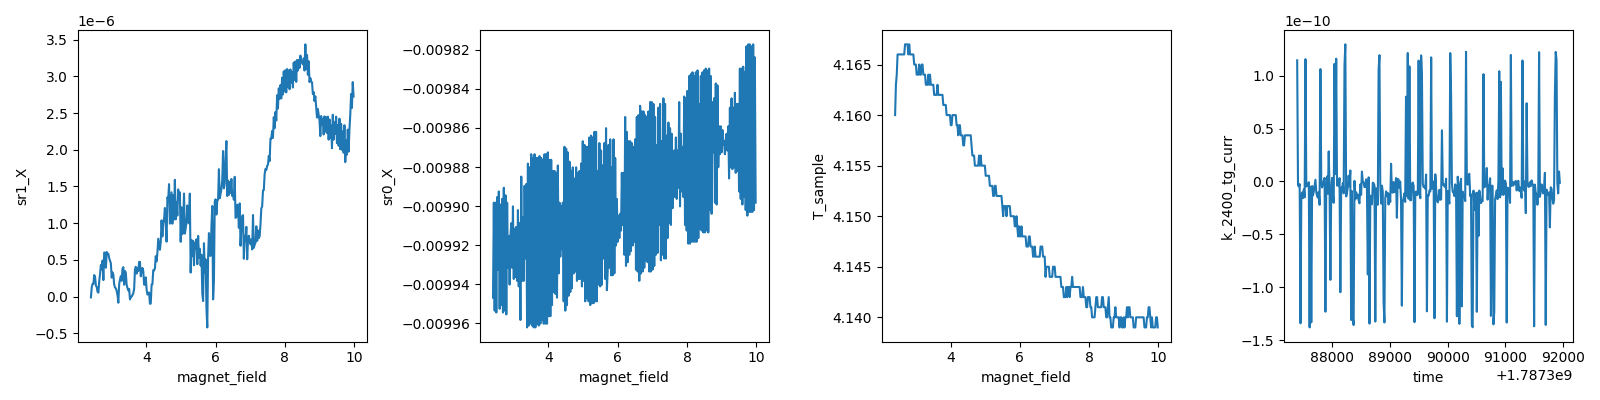

2026-08-22 02:45:45,312 [INFO] Completed in 1h 17m 2s


2026-08-22 02:45:45,313 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260821-vti-02\data\10\data.tsv.gz


T_sample: VTI_sample.txt live — age 4s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 4s, period 5s
rung 0 done at B +9.993 T; T_s 4.139 T_v 3.786 K
T_sample: VTI_sample.txt live — age 4s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 4s, period 5s


rung 1: set_both(7.0, 0.95) -> ranges 1,1; setpoints 7.0,6.65
T_sample: VTI_sample.txt live — age 1s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 1s, period 5s
  settle 7.0 K: T_s 5.999 T_v 5.600 spread90 9.900 inband False [0.0 min]


T_sample: VTI_sample.txt live — age 1s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 1s, period 5s
  settle 7.0 K: T_s 6.997 T_v 6.705 spread90 9.900 inband True [0.2 min]


...

T_sample: VTI_sample.txt live — age 5s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 5s, period 5s
  settle 7.0 K: T_s 7.018 T_v 6.653 spread90 1.038 inband True [1.2 min]


T_sample: VTI_sample.txt live — age 5s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 5s, period 5s


T_sample: VTI_sample.txt live — age 5s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 5s, period 5s


T_sample: VTI_sample.txt live — age 5s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 5s, period 5s
rung 1: T_s 7.026 K accepted; sweep 9.98 -> 2.40 T
2026-08-22 02:47:27,359 [INFO] Starting sweep with ID 11


2026-08-22 02:47:27,361 [INFO] Minimum duration 0h 3m 41s


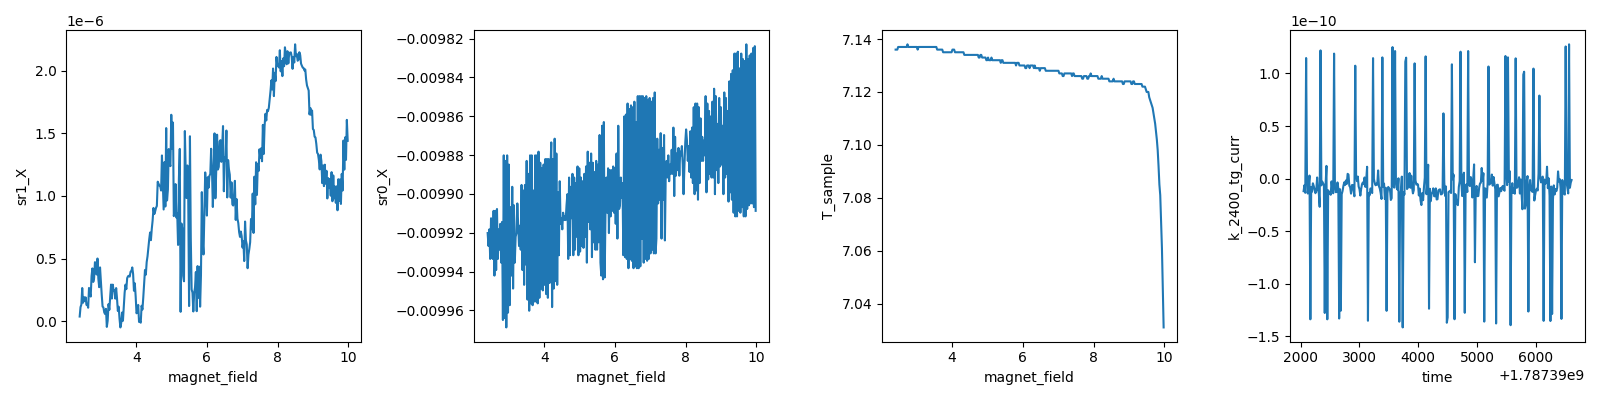

2026-08-22 04:03:25,388 [INFO] Completed in 1h 15m 57s


2026-08-22 04:03:25,389 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260821-vti-02\data\11\data.tsv.gz


T_sample: VTI_sample.txt live — age 2s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 2s, period 5s
rung 1 done at B +2.403 T; T_s 7.136 T_v 6.647 K
T_sample: VTI_sample.txt live — age 2s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 2s, period 5s


rung 2: set_both(10.0, 0.95) -> ranges 1,1; setpoints 10.0,9.5
T_sample: VTI_sample.txt live — age 4s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 4s, period 5s
  settle 10.0 K: T_s 7.136 T_v 6.647 spread90 9.900 inband False [0.0 min]


T_sample: VTI_sample.txt live — age 4s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 4s, period 5s


...

T_sample: VTI_sample.txt live — age 3s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 3s, period 5s


T_sample: VTI_sample.txt live — age 3s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 3s, period 5s


T_sample: VTI_sample.txt live — age 3s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 3s, period 5s


T_sample: VTI_sample.txt live — age 3s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 3s, period 5s
rung 2: T_s 10.010 K accepted; sweep 2.40 -> 9.98 T
2026-08-22 04:05:07,472 [INFO] Starting sweep with ID 12


2026-08-22 04:05:07,472 [INFO] Minimum duration 0h 3m 41s


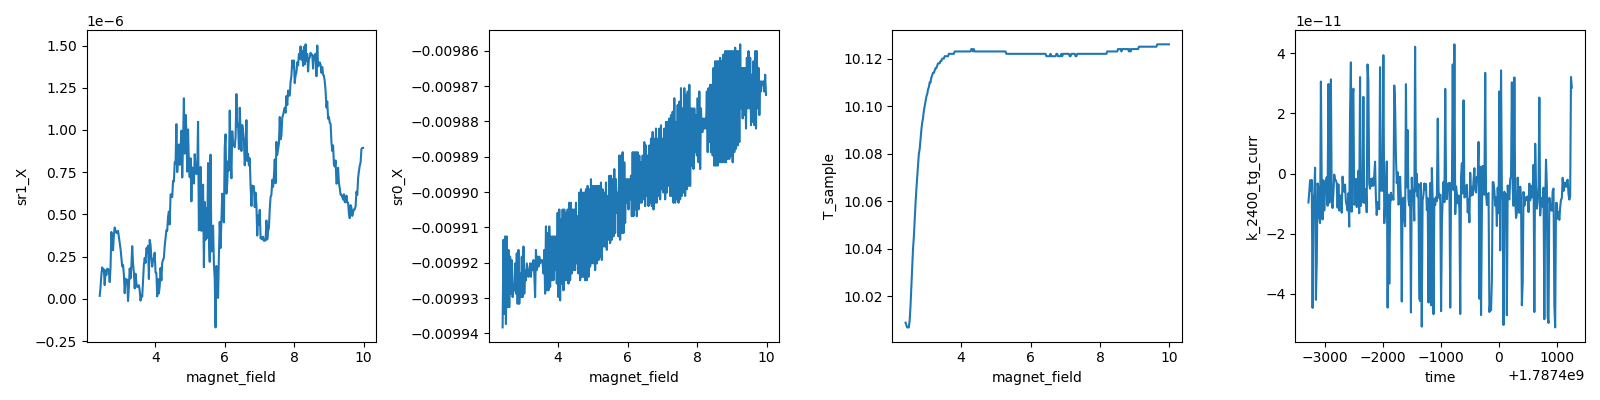

2026-08-22 05:21:04,183 [INFO] Completed in 1h 15m 56s


2026-08-22 05:21:04,184 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260821-vti-02\data\12\data.tsv.gz


T_sample: VTI_sample.txt live — age 4s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 4s, period 5s
rung 2 done at B +9.994 T; T_s 10.126 T_v 9.499 K
T_sample: VTI_sample.txt live — age 4s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 4s, period 5s


rung 3: set_both(14.0, 0.95) -> ranges 1,1; setpoints 14.0,13.3
T_sample: VTI_sample.txt live — age 1s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 1s, period 5s
  settle 14.0 K: T_s 11.245 T_v 10.324 spread90 9.900 inband False [0.0 min]


T_sample: VTI_sample.txt live — age 0s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 0s, period 5s
  settle 14.0 K: T_s 14.240 T_v 13.455 spread90 9.900 inband True [0.2 min]


...

T_sample: VTI_sample.txt live — age 5s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 5s, period 5s


T_sample: VTI_sample.txt live — age 5s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 5s, period 5s


T_sample: VTI_sample.txt live — age 5s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 5s, period 5s


T_sample: VTI_sample.txt live — age 5s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 5s, period 5s
rung 3: T_s 14.010 K accepted; sweep 9.98 -> 2.40 T
2026-08-22 05:23:06,233 [INFO] Starting sweep with ID 13


2026-08-22 05:23:06,234 [INFO] Minimum duration 0h 3m 41s


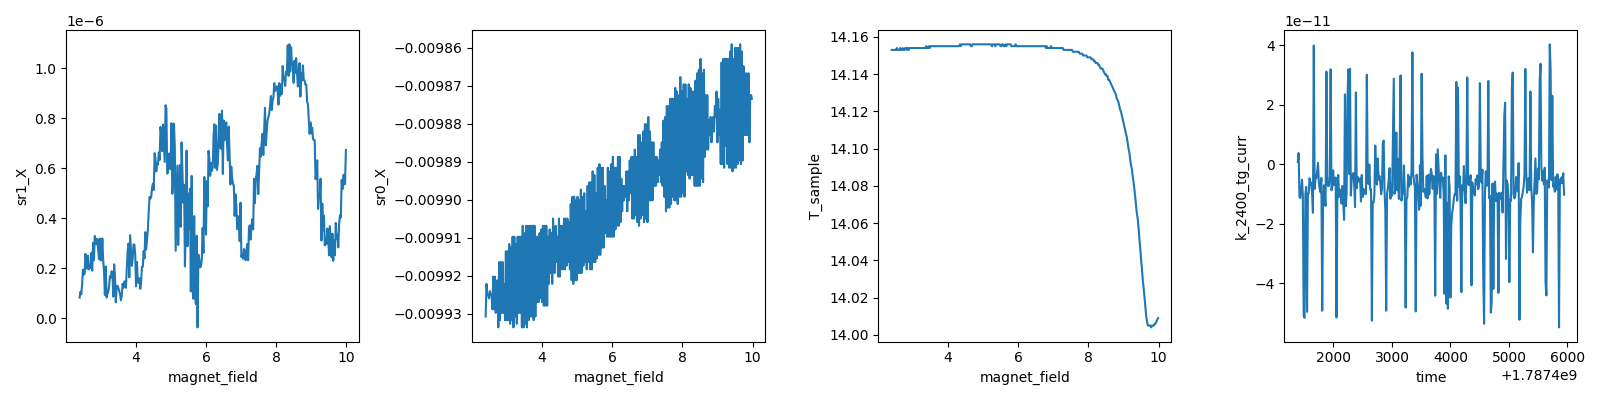

2026-08-22 06:39:03,394 [INFO] Completed in 1h 15m 56s


2026-08-22 06:39:03,396 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260821-vti-02\data\13\data.tsv.gz


T_sample: VTI_sample.txt live — age 0s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 0s, period 5s
rung 3 done at B +2.403 T; T_s 14.153 T_v 13.308 K
T_sample: VTI_sample.txt live — age 0s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 0s, period 5s


rung 4: set_both(20.0, 0.95) -> ranges 2,2; setpoints 20.0,19.0
T_sample: VTI_sample.txt live — age 2s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 2s, period 5s
  settle 20.0 K: T_s 14.153 T_v 13.308 spread90 9.900 inband False [0.0 min]


T_sample: VTI_sample.txt live — age 2s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 2s, period 5s


...

T_sample: VTI_sample.txt live — age 2s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 2s, period 5s
  settle 20.0 K: T_s 20.008 T_v 19.002 spread90 6.044 inband True [1.2 min]


T_sample: VTI_sample.txt live — age 2s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 2s, period 5s


T_sample: VTI_sample.txt live — age 1s, period 6s
T_vaporizer: VTI_vaporizer.txt live — age 1s, period 6s


T_sample: VTI_sample.txt live — age 1s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 1s, period 5s
rung 4: T_s 20.005 K accepted; sweep 2.40 -> 9.98 T
2026-08-22 06:40:45,439 [INFO] Starting sweep with ID 14


2026-08-22 06:40:45,440 [INFO] Minimum duration 0h 3m 41s


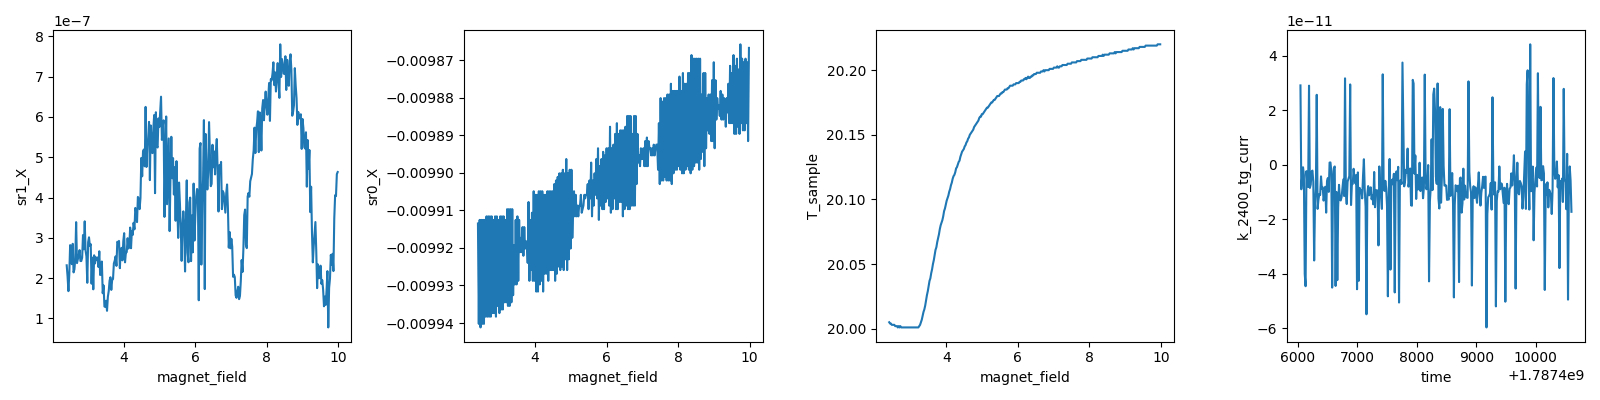

2026-08-22 07:56:39,741 [INFO] Completed in 1h 15m 53s


2026-08-22 07:56:39,742 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260821-vti-02\data\14\data.tsv.gz


T_sample: VTI_sample.txt live — age 4s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 4s, period 5s
rung 4 done at B +9.993 T; T_s 20.220 T_v 19.000 K
T_sample: VTI_sample.txt live — age 4s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 4s, period 5s


rung 5: set_both(28.0, 0.95) -> ranges 2,2; setpoints 28.0,26.6
T_sample: VTI_sample.txt live — age 6s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 6s, period 5s
  settle 28.0 K: T_s 20.220 T_v 19.000 spread90 9.900 inband False [0.0 min]


T_sample: VTI_sample.txt live — age 6s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 6s, period 5s
  settle 28.0 K: T_s 28.391 T_v 26.987 spread90 9.900 inband True [0.2 min]


...

T_sample: VTI_sample.txt live — age 5s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 5s, period 5s


T_sample: VTI_sample.txt live — age 5s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 5s, period 5s


T_sample: VTI_sample.txt live — age 5s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 5s, period 5s


T_sample: VTI_sample.txt live — age 5s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 5s, period 5s
rung 5: T_s 28.005 K accepted; sweep 9.98 -> 2.40 T
2026-08-22 07:58:31,802 [INFO] Starting sweep with ID 15


2026-08-22 07:58:31,803 [INFO] Minimum duration 0h 3m 41s


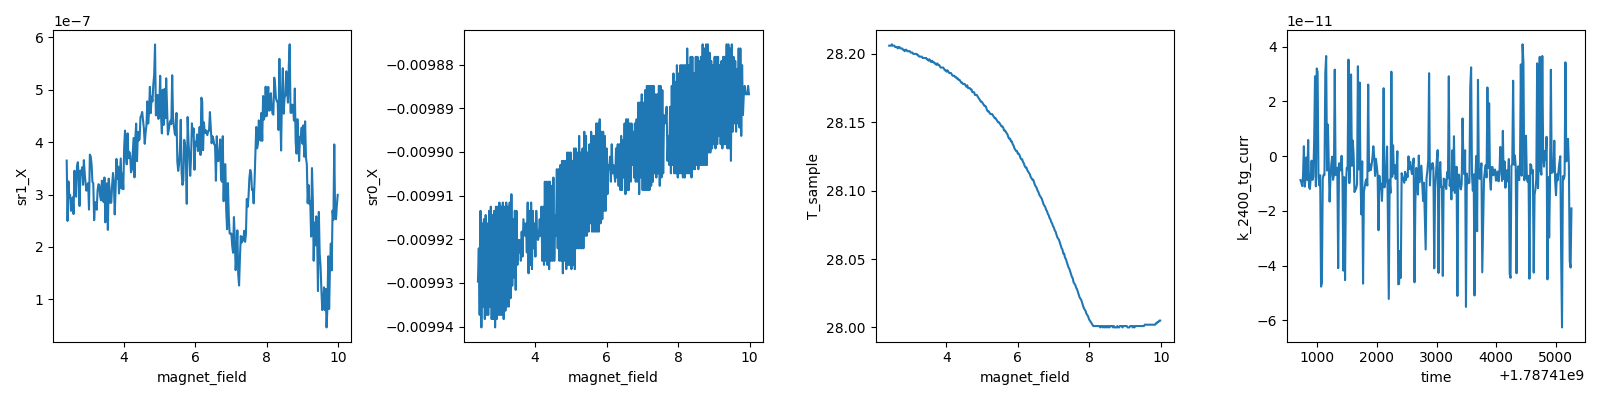

2026-08-22 09:14:24,443 [INFO] Completed in 1h 15m 52s


2026-08-22 09:14:24,444 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260821-vti-02\data\15\data.tsv.gz


T_sample: VTI_sample.txt live — age 1s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 1s, period 5s
rung 5 done at B +2.403 T; T_s 28.206 T_v 26.600 K
heaters off: ranges 0,0; B +2.403 T; gates (+0.8795, +1.2095) V; T_s 28.206 K


In [25]:
# === Verify: LK mass split — temperature-dependence-vti Flavor B at the electron spot point (n = +3.0e12 design, D = 0) ===
from sharpelab_nb.gates import calc_gate_voltages
from sharpelab_nb.autorange import autorange_sr830s
C_TG, C_BG, N_OFFSET, D_OFFSET = 2.7961e-3, 2.0330e-3, -0.069, 0.0
Vtg_spot, Vbg_spot = calc_gate_voltages(3.0, 0.0, C_TG, C_BG, n_offset=N_OFFSET, D_offset=D_OFFSET)   # (+0.879, +1.209) V, run 5's point
RUNGS = [4.0, 7.0, 10.0, 14.0, 20.0, 28.0]   # K, ascending (up-legs catch in minutes on this rig; base rung = run 5)
RATIO = 0.95                                 # rig-card sanctioned; any other value is consent-gated
B_LO, B_HI, DB = 2.4, 10.0, 0.024            # run-5 grid restricted to the above-onset window
assert max(RUNGS) <= T_SESSION_CAP and B_HI <= B_SESSION_CAP and RATIO == 0.95

def _fresh_T():
    assert_thermometry_live("T_sample", VTI.temp_logfile_candidates["T_sample"], max_age=15, max_period=12)
    assert_thermometry_live("T_vaporizer", VTI.temp_logfile_candidates["T_vaporizer"], max_age=15, max_period=12)
    return T_sample(), T_vaporizer()

def settle_hover(target, t_start_vap, timeout_s=25*60):
    """Hover acceptance (VTI variant): stable (spread < 0.1 K over 90 s) inside [target-0.5, target+3] K.
    Runaway guard: T_vap > 2 K above BOTH its rung-start value and the target -> heaters off, stop.
    Timeout: if stable (spread < 0.2 K) proceed at the actual T (it is fp'd); else stop the cell."""
    hist = []  # (t, T)
    t0 = time.time()
    while True:
        Ts, Tv = _fresh_T()
        now = time.time(); hist.append((now, Ts)); hist = [(t, T) for (t, T) in hist if now - t <= 90]
        if Tv > t_start_vap + 2.0 and Tv > target + 2.0:
            heater.off('both')
            raise RuntimeError(f"RUNAWAY: T_vap {Tv:.2f} K > start {t_start_vap:.2f}+2 and > target {target}+2 — heaters off")
        spread = max(T for _, T in hist) - min(T for _, T in hist) if len(hist) >= 6 else 9.9
        inband = (target - 0.5) <= Ts <= (target + 3.0)
        if (now - t0) % 60 < 10: print(f"  settle {target} K: T_s {Ts:.3f} T_v {Tv:.3f} spread90 {spread:.3f} inband {inband} [{(now-t0)/60:.1f} min]")
        if inband and spread < 0.1 and (now - t0) > 90:
            return Ts
        if now - t0 > timeout_s:
            if spread < 0.2:
                print(f"  settle timeout at T_s {Ts:.3f} K (stable, spread {spread:.3f}) — proceeding at the actual T")
                return Ts
            raise RuntimeError(f"settle timeout: T_s {Ts:.3f} K not stable (spread {spread:.3f}) — stopping")
        interruptible_sleep(10)

# Preconditions (assumed, not set)
Ts0, Tv0 = _fresh_T(); _B = magnet.field(); _Vsi = dc205.voltage(); _st = magnet._status()
print(f"pre: T_s {Ts0:.3f} T_v {Tv0:.3f} K | B {_B:+.3f} T | Si {_Vsi:+.3f} | heater ranges {heater.sample_range()},{heater.vaporizer_range()} | output {_st['output_enabled']} PS {_st['persistent_switch_on']}")
assert abs(_Vsi) < 0.01 and _st['output_enabled'] and _st['persistent_switch_on']
assert (abs(_B - B_LO) < 0.2) or (abs(_B - B_HI) < 0.2), "magnet must sit at an end of the ladder window"

sr1.sensitivity(2e-6)
k_tg.volt(Vtg_spot); k_bg.volt(Vbg_spot)
interruptible_sleep(5)
print(f"gates ({k_tg.volt():+.4f}, {k_bg.volt():+.4f}) V")

try:
    for i, T_rung in enumerate(RUNGS):
        Ts_pre, Tv_pre = _fresh_T()
        heater.set_both(T_rung, ratio=RATIO)
        time.sleep(2)
        print(f"rung {i}: set_both({T_rung}, {RATIO}) -> ranges {heater.sample_range()},{heater.vaporizer_range()}; setpoints {heater.sample_setpoint()},{heater.vaporizer_setpoint()}")
        assert heater.sample_range() > 0 and heater.vaporizer_range() > 0, "heater ranges did not turn on"
        T_ok = settle_hover(T_rung, Tv_pre)
        B_now = magnet.field()
        B_vec = np.arange(B_LO, B_HI + 1e-9, DB)
        if B_now > (B_LO + B_HI) / 2: B_vec = B_vec[::-1]          # alternate direction from the live field, never re-traverse
        print(f"rung {i}: T_s {T_ok:.3f} K accepted; sweep {B_vec[0]:.2f} -> {B_vec[-1]:.2f} T")
        mc = dict(meas_config); mc["comments"] = f"temperature-dependence-vti Flavor B (LK): rung {T_rung} K (T_s {T_ok:.2f}), electron (+3.0e12 design, D=0), B {B_vec[0]:.1f} -> {B_vec[-1]:.1f} T, dB 24 mT, 10 nA, Si 0"
        s = sweep.AsyncStation(mc)
        s.add_comment('temperature-dependence-vti')
        s.add_comment(f'Flavor B LK ladder, rung {i}: nominal {T_rung} K (hover-accepted T_s {T_ok:.3f} K, ratio {RATIO}); fixed point electron n = +3.0e12 design (x0.90), D = 0, (Vtg, Vbg) = ({Vtg_spot:+.4f}, {Vbg_spot:+.4f}); B {B_vec[0]:.2f} -> {B_vec[-1]:.2f} T uniform dB {DB*1e3:.0f} mT ({len(B_vec)} pts); I = 10 nA; sr1 autorange; Si = 0')
        s.add_comment('sdh-spot-check')   # same acquisition as run 5 (grid, settling, autorange) for amplitude comparison
        s.register_run_before(autorange_sr830s, (sr0, [sr1]))
        s.fp(T_sample).fp(T_vaporizer)   # logfile reads only — never poll the LS335 per point (rig card: the worker owns its GPIB)
        s.fp(k_tg.volt).fp(k_bg.volt).fp(k_tg.curr).fp(k_bg.curr)
        s.fp(sr0.X).fp(sr0.P).fp(sr1.X).fp(sr1.P)
        s.plot(magnet.field, sr1.X); s.plot(magnet.field, sr0.X); s.plot(magnet.field, T_sample); s.plot('time', k_tg.curr)
        s.sweep(magnet.field, B_vec, delay=0.7)
        Ts_end, Tv_end = _fresh_T()
        print(f"rung {i} done at B {magnet.field():+.3f} T; T_s {Ts_end:.3f} T_v {Tv_end:.3f} K")
finally:
    heater.off('both')
    print(f"heaters off: ranges {heater.sample_range()},{heater.vaporizer_range()}; B {magnet.field():+.3f} T; gates ({k_tg.volt():+.4f}, {k_bg.volt():+.4f}) V; T_s {T_sample():.3f} K")


## HERA — Close-out: `return-to-initial` (session-closeout + VTI variant)

> **09:15** · close\_out return-to-initial: state0 replay, LS335 off, gates/Si -> 0, field 2.4 -> 0 T (blocking ~18 min); readback · **ETA ~09:40** (≈25 min)

Campaign done: the call is in the ana notebook (final cell). Ladder ended at 2.40 T with heaters already off (cell above; T_s 28 K, cooling passively — base recovery is hours at ratio-free passive cooling, no heater action needed). Ask per the brief: **return-to-initial** — `close_out` replays `state0` (drive 1.0 V @ 13.777 Hz; sr0/sr1 sens and τ as at bring-up — τ 0.3 s, sr1 sens 2 µV; NPLC 1; gates 0; Si 0), LS335 ranges off (labelled callable, VTI variant), gates and Si to 0 through their own ramped parameters, then the field to the session-start value **0 T** (bring-up read 0.006 T; 2.4 T → 0 is an 18-min blocking ramp). No mux this cooldown; persistent switch / output untouched (operator-only). The readback (values + validators) is the handoff record → `session_notes.md`.


In [26]:
# === Close-out: return-to-initial (session-closeout + VTI variant) ===
# Preconditions: nothing sweeping; heaters may still be lifting from the ladder (off below, first).
from sharpelab_nb.closeout import close_out
_st = magnet._status()
print(f"pre: B {magnet.field():+.3f} T | T_s {T_sample():.3f} T_v {T_vaporizer():.3f} K | heater ranges {heater.sample_range()},{heater.vaporizer_range()} | gates ({k_tg.volt():+.4f}, {k_bg.volt():+.4f}, Si {dc205.voltage():+.3f}) | output {_st['output_enabled']} PS {_st['persistent_switch_on']}")
assert _st['output_enabled'] and _st['persistent_switch_on']

# Ask: return-to-initial -> replay state0 (drive 1.0 V @ 13.777 Hz, sr sens/tau as at bring-up, NPLC 1, gates 0, Si 0),
# LS335 ranges off (VTI variant: labelled callable), gates to 0 through their own ramped parameters, field to the
# session-start value 0 T (bring-up read 0.006 T). The field ramp blocks (~73 min from 10 T). No mux this cooldown.
# Persistent switch / output: operator-only, untouched.
close_out(
    (magnet.field, 0.0),
    restore=state0,
    heaters=[("LS335 ranges off", lambda: heater.off("both"))],
    gates=[(k_tg.volt, 0.0), (k_bg.volt, 0.0), (k_si, 0.0)],
    extra_readback={"T_sample": T_sample, "T_vaporizer": T_vaporizer,
                    "sample_range": heater.sample_range, "vaporizer_range": heater.vaporizer_range,
                    "sr1_sens": sr1.sensitivity, "sr1_tau": sr1.time_constant, "sr0_sens": sr0.sensitivity, "sr0_tau": sr0.time_constant,
                    "Si_V": dc205.voltage, "dc205_range": dc205.voltage_range, "dc205_output": dc205.output},
)


pre: B +2.406 T | T_s 28.182 T_v 23.499 K | heater ranges 0,0 | gates (+0.8795, +1.2095, Si +0.000) | output True PS True
-- restore (19 params)


-- heaters
   LS335 ranges off
-- gates
-- field -> 0.0



--- close-out readback ---
drive_V : 1.0  <Numbers 0.004<=v<=5.0>
drive_Hz : 13.777  <Numbers 0.001<=v<=102000.0>
sr0_sens : 0.02  <Enum: {0.2, 0.5, 2e-09, 1, 1e-08, 5e-05, 2e-08, 0.0001, 0.05, 0.0002, 5e-06, 5e-08, 1e-06, 0.1, 5e-09, 2e-05, 0.02, 5e-07, 1e-05, 0.01, 2e-07, 0.005, 1e-07, 2e-06, 0.002, 0.001, 0.0005}>
sr0_tau : 0.3  <Enum: {0.3, 1, 3, 10, 10000.0, 0.0001, 30, 300, 30000.0, 3000.0, 3e-05, 0.03, 0.1, 0.0003, 100, 1e-05, 1000.0, 0.01, 0.003, 0.001}>
sr0_slope : 24  <Enum: {24, 18, 12, 6}>
sr1_sens : 2e-06  <Enum: {0.2, 0.5, 2e-09, 1, 1e-08, 5e-05, 2e-08, 0.0001, 0.05, 0.0002, 5e-06, 5e-08, 1e-06, 0.1, 5e-09, 2e-05, 0.02, 5e-07, 1e-05, 0.01, 2e-07, 0.005, 1e-07, 2e-06, 0.002, 0.001, 0.0005}>
sr1_tau : 0.3  <Enum: {0.3, 1, 3, 10, 10000.0, 0.0001, 30, 300, 30000.0, 3000.0, 3e-05, 0.03, 0.1, 0.0003, 100, 1e-05, 1000.0, 0.01, 0.003, 0.001}>
sr1_slope : 24  <Enum: {24, 18, 12, 6}>
sr2_sens : 0.0001  <Enum: {0.2, 0.5, 2e-09, 1, 1e-08, 5e-05, 2e-08, 0.0001, 0.05, 0.0002, 5e-06, 5

V_bg : 0.0  <Numbers -1.3<=v<=2.0>
V_si : 0.0  <Numbers -25.0<=v<=25.0>
field : 0.0027410273972602738 T  <Numbers -10.0<=v<=10.0>
T_sample : 1.251
T_vaporizer : 0.964
sample_range : 0
vaporizer_range : 0
sr1_sens : 2e-06  <Enum: {0.2, 0.5, 2e-09, 1, 1e-08, 5e-05, 2e-08, 0.0001, 0.05, 0.0002, 5e-06, 5e-08, 1e-06, 0.1, 5e-09, 2e-05, 0.02, 5e-07, 1e-05, 0.01, 2e-07, 0.005, 1e-07, 2e-06, 0.002, 0.001, 0.0005}>
sr1_tau : 0.3  <Enum: {0.3, 1, 3, 10, 10000.0, 0.0001, 30, 300, 30000.0, 3000.0, 3e-05, 0.03, 0.1, 0.0003, 100, 1e-05, 1000.0, 0.01, 0.003, 0.001}>
sr0_sens : 0.02  <Enum: {0.2, 0.5, 2e-09, 1, 1e-08, 5e-05, 2e-08, 0.0001, 0.05, 0.0002, 5e-06, 5e-08, 1e-06, 0.1, 5e-09, 2e-05, 0.02, 5e-07, 1e-05, 0.01, 2e-07, 0.005, 1e-07, 2e-06, 0.002, 0.001, 0.0005}>
sr0_tau : 0.3  <Enum: {0.3, 1, 3, 10, 10000.0, 0.0001, 30, 300, 30000.0, 3000.0, 3e-05, 0.03, 0.1, 0.0003, 100, 1e-05, 1000.0, 0.01, 0.003, 0.001}>
Si_V : 0.0  <Numbers -25.0<=v<=25.0>
dc205_range : 2
dc205_output : 1
